# Proyecto: Venteo y Quema de Gas

**Pregunta de investigación:** ¿Qué **ubicación** y **época del año** se asocian con que un mes de producción tenga una **pérdida significativa** de gas (venteo + quema superior al 10 % del volumen total)?

El objetivo es identificar **asociaciones** en datos observacionales. No se afirma causalidad.

**Cambios respecto a la versión anterior:**
1. **Unidad de análisis:** ubicación × mes, con una tasa de pérdida volumétrica, en lugar de cada renglón administrativo.
2. **Partición temporal:** entrenamiento 2015–2023, verificación 2024–2025. La validación cruzada también respeta el orden temporal.
3. **Comparación con regresión:** se predice la tasa de pérdida y se compara con la clasificación usando el mismo umbral.

**Fuente:** `OGORBcsv.csv` (producción y disposición de hidrocarburos, mensual, 2015-01 a 2025-05).

**Recuperado de:** https://revenuedata.onrr.gov/downloads/production-by-disposition/

## Parte 1 - Carga de librerias y Dataset

### 1.1 - Librerias

In [1]:
# === Librerías estándar ===
import re
import warnings

# === Manipulación y visualización ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# === Modelos (scikit-learn) ===
from sklearn.cluster import KMeans, DBSCAN
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, Ridge

# === Preprocesamiento, pipelines y utilidades ===
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# === Validación y métricas ===
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_validate
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    accuracy_score, adjusted_rand_score, average_precision_score,
    classification_report, confusion_matrix, mean_absolute_error,
    precision_score, r2_score, recall_score, roc_auc_score,
    silhouette_score,
)

# === Configuración global ===
warnings.filterwarnings("ignore")  # ver nota 3
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42  # semilla fija para que los resultados con aleatoriedad sean reproducibles

### 1.2 - Carga y presentacion del dataset

In [2]:
RUTA = 'OGORBcsv.csv'
df = pd.read_csv(RUTA) 
print('Dimensiones:', df.shape)
df.head()

Dimensiones: (470830, 11)


,Production Date,Land Class,Land Category,State,County,FIPS Code,Offshore Region,Commodity,Disposition Code,Disposition Description,Volume
0,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0
1,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,"14,508,756"
2,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,"1,207,520"
3,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,"487,324"
4,01/01/2015,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,"114,808"


In [3]:
df.tail()

,Production Date,Land Class,Land Category,State,County,FIPS Code,Offshore Region,Commodity,Disposition Code,Disposition Description,Volume
470825,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),62,Vented Gas Well Gas - Royalty Not Due,0
470826,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),66,Flared Oil Well Gas - Royalty Due,0
470827,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),67,Flared Gas Well Gas - Royalty Due,0
470828,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),68,Vented Oil Well Gas - Royalty Due,0
470829,05/01/2025,Native American,Onshore,NaN,NaN,NaN,NaN,Oil (bbl),69,Vented Gas Well Gas - Royalty Due,0


### 1.3 - Normalizar nombres de las columnas

In [4]:
# Normalización de nombres de columnas
df.columns = [re.sub(r'\s+', '_', c.strip().lower()) for c in df.columns]
print(df.columns.tolist())

['production_date', 'land_class', 'land_category', 'state', 'county', 'fips_code', 'offshore_region', 'commodity', 'disposition_code', 'disposition_description', 'volume']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 470830 entries, 0 to 470829
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   production_date          470830 non-null  str    
 1   land_class               470830 non-null  str    
 2   land_category            470830 non-null  str    
 3   state                    454200 non-null  str    
 4   county                   454200 non-null  str    
 5   fips_code                454200 non-null  float64
 6   offshore_region          10196 non-null   str    
 7   commodity                470830 non-null  str    
 8   disposition_code         470830 non-null  int64  
 9   disposition_description  470830 non-null  str    
 10  volume                   470830 non-null  str    
dtypes: float64(1), int64(1), str(9)
memory usage: 39.5 MB


Observo que hay un total de 470830 filas y 11 columnas.

La mayoría son variables categóricas, a excepción de flips code y disposition code. También me doy cuenta que hay un error respecto a los valores de volumen.

Estos se muestran como "str" cuando son valores numéricos. Esto se debe a que hay "," en los valores. Es necesario solucionar esto.

## Parte 2 - Analisis de datos


### 2.1 - Problema 1: formato numérico de `volume`
Comprobamos el formato real y la conversión antes de aplicarla.

In [6]:
#Me traico 5 valores para comprobar esto de "," en la unidad de volumen
print('Ejemplos con separador de miles:')
print(df.loc[df['volume'].str.contains(','), 'volume'].head(5).tolist())

#Cuenta los valores que esten vacios o solo contienen espacios. Valores como NaN o 0 no se cuentan
print('\nValores vacíos en volume:', (df['volume'].str.strip() == '').sum())

#Cambio el "," del dataset y lo pego en la misma columna
df['volume'] = pd.to_numeric(df['volume'].str.replace(',', '', regex=False), errors='coerce')

#Veo valores negativos
print('Valores negativos:', (df['volume'] < 0).sum())

print('Verificación del tipo de dato:', df['volume'].dtype)


Ejemplos con separador de miles:
['14,508,756', '1,207,520', '487,324', '114,808', '1,160']

Valores vacíos en volume: 0
Valores negativos: 13036
Verificación del tipo de dato: int64


### 2.2 - Unidades físicas distintas (gas en Mcf vs. petróleo en bbl)
Verificamos que `commodity` separe ambas unidades. **No se suman volúmenes de gas y petróleo.**

In [7]:
# Se usa la columna 'volume' ya convertida a numérico
print(df.groupby('commodity')['volume'].agg(['count', 'sum']))
print('\nLa suma de gas y petróleo NO es una magnitud válida: se trabaja solo con Gas (Mcf).')

            count          sum
commodity                     
Gas (Mcf)  235415  51194121625
Oil (bbl)  235415  11224187465

La suma de gas y petróleo NO es una magnitud válida: se trabaja solo con Gas (Mcf).


### 2.3 - Problema 3: formato de `production_date`
El formato es `MM/DD/YYYY` con día siempre 01. Verificamos antes de convertir.

In [8]:
# 1) Patrón de formato (sin cambios)
print('Formatos únicos (patrón):', df['production_date'].str.replace(r'\d', '9', regex=True).unique())

# 2) Parsear primero, sin modificar el dataframe todavía
fechas = pd.to_datetime(df['production_date'], format='%m/%d/%Y', errors='coerce')

print('Fechas no interpretables:', fechas.isna().sum())

# 3) Verificar el día real
print('Días distintos de 1:', (fechas.dt.day != 1).sum())
print(fechas.dt.day.value_counts())

# 4) Verificar la cobertura mensual
print('Meses distintos:', fechas.dt.to_period('M').nunique())
print(fechas.dt.month.value_counts().sort_index())

# 5) Asignar al dataframe
df['production_date'] = fechas
print('Rango:', df['production_date'].min().date(), '->', df['production_date'].max().date())

Formatos únicos (patrón): <StringArray>
['99/99/9999']
Length: 1, dtype: str
Fechas no interpretables: 0
Días distintos de 1: 0
production_date
1    470830
Name: count, dtype: int64
Meses distintos: 125
production_date
1     41384
2     41448
3     41534
4     41510
5     41224
6     37798
7     37650
8     37802
9     37606
10    37746
11    37636
12    37492
Name: count, dtype: int64
Rango: 2015-01-01 -> 2025-05-01


### 2.4 - Problema 4: códigos de disposición
Construimos la tabla de correspondencia **antes** de sumar nada.

Clasificación adoptada (documentada en el informe):
- **Venta comercial (gas):** 01, 04, 05, 06, 09, 07, 15, 43.
- **Venteo:** 61, 62, 63, 68, 69 (*Vented*).
- **Quema / flaring:** 21, 22, 33, 66, 67 (*Flared*).
- **Otros destinos internos o contables** (11 transferido a instalación, 20 uso en lugar, 14 inyección, 42 ajustes, 25 buy-back, etc.): **no son venta ni pérdida**, se excluyen.

In [9]:
relacion = (
    df[['disposition_code', 'disposition_description']]
    .drop_duplicates()
    .sort_values(['disposition_code', 'disposition_description'])
    .reset_index(drop=True)
)

relacion

,disposition_code,disposition_description
0,1,Sales-Royalty Due-MEASURED
1,3,Load Oil
2,4,Sales-Royalty Due-Not Measured
3,5,"Sales-Royalty Not Due, Recovered Injection-MEA..."
4,6,Sales-Non-Hydrocarbon Gas
5,7,Condensate Sales-Royalty Due-MEASURED
6,8,Spilled and/or Lost-Avoidable-Royalty Due
7,9,Sales-Royalty Not Due-MEASURED
8,10,Produced into Inventory Prior to Sales
9,11,Transferred to Facility


In [10]:
df_gas = df.loc[df['commodity'].eq('Gas (Mcf)')].copy()

descripcion = (
    df_gas['disposition_description']
    .fillna('')
    .astype('string')
    .str.strip()
)

coincidencias = pd.DataFrame({
    'Sales': descripcion.str.contains(
        r'\b(sale|sales|sold)\b', case=False, na=False
    ),
    'Vented': descripcion.str.contains(
        r'\b(vent|vented|venting)\b', case=False, na=False
    ),
    'Flared': descripcion.str.contains(
        r'\b(flare|flared|flaring)\b', case=False, na=False
    )
}, index=df_gas.index)

df_gas['tipo_disposicion'] = np.select(
    [
        coincidencias['Sales'] & coincidencias.sum(axis=1).eq(1),
        coincidencias['Vented'] & coincidencias.sum(axis=1).eq(1),
        coincidencias['Flared'] & coincidencias.sum(axis=1).eq(1)
    ],
    ['Sales', 'Vented', 'Flared'],
    default='Revisar'
)

tabla_tipos = (
    df_gas.groupby(
        ['tipo_disposicion', 'disposition_code', 'disposition_description'],
        dropna=False
    )
    .size()
    .reset_index(name='registros')
    .sort_values(['tipo_disposicion', 'disposition_code'])
    .reset_index(drop=True)
)

tabla_tipos

,tipo_disposicion,disposition_code,disposition_description,registros
0,Flared,21,Flared Oil Well Gas - Royalty Not Due,8986
1,Flared,22,Flared Gas Well Gas - Royalty Not Due,4567
2,Flared,33,Flared Gas - Royalty Due,2884
3,Flared,66,Flared Oil Well Gas - Royalty Due,2445
4,Flared,67,Flared Gas Well Gas - Royalty Due,572
5,Revisar,3,Load Oil,90
6,Revisar,8,Spilled and/or Lost-Avoidable-Royalty Due,1206
7,Revisar,11,Transferred to Facility,17465
8,Revisar,12,Transferred to Facility-Returned to L/A,1496
9,Revisar,13,Transferred from Facility,5264


In [11]:
#Creo las columnas
VENTA = [1, 4, 5, 6, 7, 9, 15, 43]
VENTEO = [61, 62, 63, 68, 69]
QUEMA = [21, 22, 33, 66, 67]

#Creo una copia con el df original y creo otro llamado gas. Este es el que vamos a trabajar
gas = df[df['commodity'] == 'Gas (Mcf)'].copy()

#Defino la funcion
def categorizar(c):
    if c in VENTA:  return 'venta'
    if c in VENTEO: return 'venteo'
    if c in QUEMA:  return 'quema'
    return 'otro'

#Agrego una columna "categoria" para diferenciar los tipos de disposicion
gas['categoria'] = gas['disposition_code'].map(categorizar)

#Creo la tabla agrupando los valores que necesitamos
tabla_codigos = (gas.groupby(['disposition_code', 'disposition_description', 'categoria'])
                    .agg(registros=('volume', 'size'), volumen_mcf=('volume', 'sum'))
                    .reset_index())

#Ordeno la tabla
orden = ['venta', 'venteo', 'quema', 'otro']

tabla_codigos['categoria'] = pd.Categorical(
    tabla_codigos['categoria'],
    categories=orden,
    ordered=True
)

tabla_codigos = tabla_codigos.sort_values(
    ['categoria', 'disposition_code']
).reset_index(drop=True)


tabla_codigos

,disposition_code,disposition_description,categoria,registros,volumen_mcf
0,1,Sales-Royalty Due-MEASURED,venta,31512,12783398822
1,4,Sales-Royalty Due-Not Measured,venta,3477,31071152
2,5,"Sales-Royalty Not Due, Recovered Injection-MEA...",venta,377,119447925
3,6,Sales-Non-Hydrocarbon Gas,venta,847,2951838075
4,7,Condensate Sales-Royalty Due-MEASURED,venta,386,0
5,9,Sales-Royalty Not Due-MEASURED,venta,1548,1676110371
6,15,Sales-Buy-Back-Measured-Royalty Not Due,venta,1831,1334022108
7,43,Sales-Royalty Not Due-FMP Not Assigned,venta,39,1254
8,61,Vented Oil Well Gas - Royalty Not Due,venteo,4400,23170382
9,62,Vented Gas Well Gas - Royalty Not Due,venteo,3935,14168710


### 2.5 - Resumen de todas las correcciones

In [12]:

informe = pd.DataFrame([
    ['volume', 'Texto con comas de miles', 'Conversión numérica tras quitar comas',
     f"{len(df):,} registros", f"No convertibles: {df['volume'].isna().sum()}"],

    ['Unidades', 'Gas (Mcf) y Petróleo (bbl) mezclados', 'Filtro solo Gas (Mcf)',
     f"{(df['commodity']!='Gas (Mcf)').sum():,} petróleo excluido", 'Sin suma cruzada'],

    ['production_date', 'MM/DD/YYYY, día 01', 'pd.to_datetime con formato explícito',
     f"{df['production_date'].isna().sum()} no válidas", 'Rango 2015-01 a 2025-05'],

    ['disposition_code', '33 códigos', 'Tabla de correspondencia documentada',
     f"{gas['categoria'].value_counts().get('otro', 0):,} de gas excluidos (otros destinos)",
     'Solo venta/venteo/quema en el análisis'],

], columns=['Problema', 'Diagnóstico', 'Corrección', 'Registros afectados', 'Validación'])

informe

,Problema,Diagnóstico,Corrección,Registros afectados,Validación
0,volume,Texto con comas de miles,Conversión numérica tras quitar comas,"470,830 registros",No convertibles: 0
1,Unidades,Gas (Mcf) y Petróleo (bbl) mezclados,Filtro solo Gas (Mcf),"235,415 petróleo excluido",Sin suma cruzada
2,production_date,"MM/DD/YYYY, día 01",pd.to_datetime con formato explícito,0 no válidas,Rango 2015-01 a 2025-05
3,disposition_code,33 códigos,Tabla de correspondencia documentada,"166,451 de gas excluidos (otros destinos)",Solo venta/venteo/quema en el análisis


## Parte 3 - Limpieza y preparacion del dataset

- Se trabaja solo con gas.
- Se usan los registros venta, venteo y quema. Los demás destinos se excluyen.
- Los valores negativos de `volume` se **truncan a cero** solo para el cálculo de proporciones de disposición (representan reversiones y no volumen vendido/perdido). Se documenta.
- Se revisan duplicados y valores faltantes en las variables clave.

### 3.1 - Limpio el dataset
Excluyos los datos del dataset que no vamos a usar. Para ello creamos otro dataset llamado gas_limpio.

Básicamente saco las filas que no vamos a usar

In [13]:
#Creo una nueva copia con el dataframe que vamos a trabajar
gas_limpio = gas[gas['categoria'].isin(['venta', 'venteo', 'quema'])].copy()
#Una alternativa a esto es trabajar con el mismo df: gas pero haciendo drop de las filas con categoria: otros
#Con isin me devuelve True si la categoria es correcta y lo copia

#Creo una nueva columna "Perdida" para considerar los valores de venteo y quema
gas_limpio['perdida'] = gas_limpio['categoria'].isin(['venteo', 'quema']).astype(int)

#Reseteo el indice
gas_limpio.reset_index(drop=True, inplace=True)
gas_limpio.head()


,production_date,land_class,land_category,state,county,fips_code,offshore_region,commodity,disposition_code,disposition_description,volume,categoria,perdida
0,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0,venta,0
1,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,14508756,venta,0
2,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,1207520,venta,0
3,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,487324,venta,0
4,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,114808,venta,0


### 3.2 - Valores duplicados 

In [14]:
#Comparo y verifico si hay algun valor duplicado
print('Registros de gas totales:', len(gas)) 
print('Registros en el análisis:', len(gas_limpio))
print('Duplicados exactos en el df limpio:', gas_limpio.duplicated().sum())
#No hay valores duplicados

Registros de gas totales: 235415
Registros en el análisis: 68964
Duplicados exactos en el df limpio: 0


In [15]:
gas_limpio.info()

<class 'pandas.DataFrame'>
RangeIndex: 68964 entries, 0 to 68963
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   production_date          68964 non-null  datetime64[us]
 1   land_class               68964 non-null  str           
 2   land_category            68964 non-null  str           
 3   state                    65351 non-null  str           
 4   county                   65351 non-null  str           
 5   fips_code                65351 non-null  float64       
 6   offshore_region          2077 non-null   str           
 7   commodity                68964 non-null  str           
 8   disposition_code         68964 non-null  int64         
 9   disposition_description  68964 non-null  str           
 10  volume                   68964 non-null  int64         
 11  categoria                68964 non-null  str           
 12  perdida                  68964 non-null  in

### 3.3 - Valores sin aporte de informacion

Aca lo que busco ver es la cantidad de informacion que tiene cada columna. Si en una columna solo hay un valor o dos (dependiendo el caso) es muy probable que esa informacion que contiene no es mucha o buena

En este caso vemos que solo commodity posee un valor pero es logico ya que filtramos por Gas. Asi que esta bien

Por otro lado el resto de variables categoricas que poseen 2 o 3 valores tambien son correctas.

In [16]:
Var_sin_info = gas_limpio.nunique().sort_values()
print("\nValores distintos por columna:")
print(Var_sin_info.head(13))


Valores distintos por columna:
commodity                      1
land_category                  2
perdida                        2
offshore_region                3
categoria                      3
land_class                     3
disposition_code              18
disposition_description       18
state                         26
production_date              125
county                       281
fips_code                    315
volume                     25707
dtype: int64


### 3.4 - Nuevas Variables y Volumen negativos

Voy a crear variables derivadas respecto al tiempo creando asi columnas que agrupen año, mes y estacion.
Estas es posible que las utilice para nuestro modelo predictivo y nos pueda permitir presentar la informacion mas detallada.

Por otro lado nos damos cuenta que hay volumenes negativos. Esto es por muchas razones pero a la hora de los calculos matematicos nos perjudicaria asi que hacemos que los valores que negativos pasen a ser 0 y los valores positivos y nulos quedaran igual

'Aclaracion:'  Los valores NaN o faltantes no seran reemplazados en ninguno de los casos descriptos. En otro apartado se realizara el analisis sobre estos



In [17]:

#Creo la columnas temporales por si necesito usarla mas adelante
gas_limpio['year'] = gas_limpio['production_date'].dt.year
gas_limpio['month'] = gas_limpio['production_date'].dt.month
gas_limpio['season'] = gas_limpio['month'].map({
    12: 'Invierno', 1: 'Invierno', 2: 'Invierno',
    3: 'Primavera', 4: 'Primavera', 5: 'Primavera',
    6: 'Verano', 7: 'Verano', 8: 'Verano',
    9: 'Otoño', 10: 'Otoño', 11: 'Otoño'
})

#Hay volumenes negativos. Con esto quiero que los negativos pasen a ser 0, los positivos y nulos queden igual
#Esto es para que no me afecte en los calculos
gas_limpio['vol_pos'] = gas_limpio['volume'].clip(lower=0)
gas_limpio.head()



,production_date,land_class,land_category,state,county,fips_code,offshore_region,commodity,disposition_code,disposition_description,volume,categoria,perdida,year,month,season,vol_pos
0,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Alaska,Gas (Mcf),1,Sales-Royalty Due-MEASURED,0,venta,0,2015,1,Invierno,0
1,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),1,Sales-Royalty Due-MEASURED,14508756,venta,0,2015,1,Invierno,14508756
2,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),1,Sales-Royalty Due-MEASURED,1207520,venta,0,2015,1,Invierno,1207520
3,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Gulf,Gas (Mcf),4,Sales-Royalty Due-Not Measured,487324,venta,0,2015,1,Invierno,487324
4,2015-01-01,Federal,Offshore,NaN,NaN,NaN,Offshore Pacific,Gas (Mcf),4,Sales-Royalty Due-Not Measured,114808,venta,0,2015,1,Invierno,114808


In [18]:
#Verifico los valores negativos
# Negativos en el dataset completo y en el subconjunto analizado
print('Negativos en df completo:', (df['volume'] < 0).sum())
print('Negativos en gas_limpio:', (gas_limpio['volume'] < 0).sum())

# Dónde están los negativos del dataset completo (por código)
print(df.loc[df['volume'] < 0, 'disposition_code'].value_counts().sort_index())

# Ceros en gas_limpio, por categoría (son legítimos, solo se cuentan)
print(gas_limpio.loc[gas_limpio['volume'] == 0, 'categoria'].value_counts())

# ¿vol_pos es distinta de volume en algún registro?
print('Filas donde volume != vol_pos:', (gas_limpio['volume'] != gas_limpio['vol_pos']).sum())

Negativos en df completo: 13036
Negativos en gas_limpio: 0
disposition_code
13    5815
25    3921
42    3300
Name: count, dtype: int64
categoria
venta     2881
quema      562
venteo     527
Name: count, dtype: int64
Filas donde volume != vol_pos: 0


### 3.5 - Valores faltantes

In [19]:
#Veo las filas para no perderlo de vista
print('\nLa cantidad de filas originales son:')
print(gas_limpio.shape)

#Calculo faltantes
print('\nValores faltantes en variables clave:')
print(gas_limpio.isna().sum())



La cantidad de filas originales son:
(68964, 17)

Valores faltantes en variables clave:
production_date                0
land_class                     0
land_category                  0
state                       3613
county                      3613
fips_code                   3613
offshore_region            66887
commodity                      0
disposition_code               0
disposition_description        0
volume                         0
categoria                      0
perdida                        0
year                           0
month                          0
season                         0
vol_pos                        0
dtype: int64


In [20]:
print('\n Proporcion de valores faltantes:')
print(gas_limpio.isna().mean()*100)


 Proporcion de valores faltantes:
production_date            0.0000
land_class                 0.0000
land_category              0.0000
state                      5.2390
county                     5.2390
fips_code                  5.2390
offshore_region           96.9883
commodity                  0.0000
disposition_code           0.0000
disposition_description    0.0000
volume                     0.0000
categoria                  0.0000
perdida                    0.0000
year                       0.0000
month                      0.0000
season                     0.0000
vol_pos                    0.0000
dtype: float64


Ahora quiero analizar porque faltan esos valores. En esto noto dos patrones comunes y realizo una hipotesis en base a ello y lo verifico

1. Columna Offshore Region
    En este caso voy puede pasar que la zona si sea offshore y me figure en Land category o puede pasar que el 97% de los pozos son Onshore y en consecuencia, no tienen valores en esta columna. Lo cual es logico

2. Columnas State, County y flips Code
    Estas columnas tienen exactamente la misma cantidad de datos faltantes. Asi que puedo interpretar que al no tener estado, no tiene county y en consecuencia no tiene flips code
    Voy a ver primero que datos posee estas columnas e intentar ver el motivo por el cual faltan
    



In [21]:
# 1) Diagnóstico: cuántos faltantes hay y en qué land_category están
print(gas_limpio['offshore_region'].isna().sum())
print(gas_limpio.loc[gas_limpio['offshore_region'].isna(), 'land_category'].value_counts(dropna=False))

66887
land_category
Onshore    66887
Name: count, dtype: int64


In [22]:
#Hipotesis 2
cols = ['state', 'county', 'fips_code']

# Patrones: cuántas filas tienen faltantes en 0, 1, 2 o las 3 columnas
n_faltantes = gas_limpio[cols].isna().sum(axis=1)
print(n_faltantes.value_counts().sort_index())

# Combinaciones exactas de faltantes (qué columnas faltan juntas)
patrones = gas_limpio[cols].isna().value_counts()
print(patrones)


0    65351
3     3613
Name: count, dtype: int64
state  county  fips_code
False  False   False        65351
True   True    True          3613
Name: count, dtype: int64


In [23]:
# ¿Los faltantes coinciden con offshore o con alguna state en particular?
print(pd.crosstab(gas_limpio['land_category'], gas_limpio['state'].isna(), dropna=False))
print(pd.crosstab(gas_limpio['offshore_region'].fillna('vacío'), gas_limpio['state'].isna()))

state          False  True 
land_category              
Offshore           0   2077
Onshore        65351   1536
state             False  True 
offshore_region               
Offshore Alaska       0    373
Offshore Gulf         0   1274
Offshore Pacific      0    430
vacío             65351   1536


Hay dos tablas
En la primera es state vs Land category
Hay 2077 valores faltantes de state con land category de offshore lo cual es logico
Sin embargo hay 1536 valores faltantes de state en land category = onshore. Este dato si es importante porque falta

El cruce de la siguiente tabla de state vs offshore_region me permite verificar lo que mencionamos


In [24]:
gas_limpio = gas_limpio.copy()

# 1) offshore_region: los NaN corresponden solo a tierra onshore (verificado: 66.887 = 66.887)
assert gas_limpio.loc[gas_limpio['land_category'].eq('Offshore'), 'offshore_region'].notna().all(), \
    'Hay registros offshore sin región'
gas_limpio['offshore_region'] = gas_limpio['offshore_region'].fillna('No aplica (onshore)')

# 2) state y county: motivo del faltante, verificado con los crosstabs
motivo = np.select(
    [gas_limpio['land_category'].eq('Offshore'),
     gas_limpio['land_class'].eq('Native American')],
    ['No aplica (offshore)', 'No reportado (tierra indígena)'],
    default='Sin dato'
)

gas_limpio['state'] = gas_limpio['state'].where(gas_limpio['state'].notna(), motivo)
gas_limpio['county'] = gas_limpio['county'].where(gas_limpio['county'].notna(), motivo)

# 3) Verificaciones
print(gas_limpio['offshore_region'].value_counts(dropna=False))
print(gas_limpio['state'].value_counts(dropna=False))
assert gas_limpio['offshore_region'].notna().all(), 'Quedan NaN en offshore_region'
assert gas_limpio['state'].notna().all(), 'Quedan NaN en state'
assert gas_limpio['county'].notna().all(), 'Quedan NaN en county'
assert len(gas_limpio) == 68964, 'Cambió el número de filas'

offshore_region
No aplica (onshore)    66887
Offshore Gulf           1274
Offshore Pacific         430
Offshore Alaska          373
Name: count, dtype: int64
state
WY                                10451
NM                                 7163
CO                                 6511
OK                                 5927
ND                                 5842
TX                                 4798
MT                                 4109
UT                                 2989
LA                                 2741
CA                                 2629
AR                                 2521
No aplica (offshore)               2077
No reportado (tierra indígena)     1536
AK                                 1401
MS                                 1332
KS                                 1286
OH                                 1215
KY                                  958
MI                                  730
WV                                  579
SD                                  

In [25]:
#Verificacion final
gas_limpio.isna().sum()

production_date               0
land_class                    0
land_category                 0
state                         0
county                        0
fips_code                  3613
offshore_region               0
commodity                     0
disposition_code              0
disposition_description       0
volume                        0
categoria                     0
perdida                       0
year                          0
month                         0
season                        0
vol_pos                       0
dtype: int64

No haremos ninguna correccion sobre fips_code ya que vamos a descartarla mas adelante cuando trabajemos con nuestro modelo

#### Justificación completa

Las variables geográficas presentan faltantes con causas distintas, por lo que cada una recibe un tratamiento específico. No se usa una etiqueta genérica para todos los casos.

**Causas de los faltantes**

- `offshore_region`: los 66.887 faltantes corresponden exactamente a registros de tierra onshore (`land_category = Onshore`). No es un dato perdido sino una categoría que no aplica, porque una región offshore no existe en tierra firme.
- `state` y `county`: los 3.613 faltantes tienen dos orígenes verificados con tablas cruzadas:
  - 2.077 registros offshore (`land_category = Offshore`), donde el estado no aplica.
  - 1.536 registros de tierra indígena (`land_class = Native American`), donde el estado no fue reportado.
  
  Las tierras federales y de exploración mixta siempre tienen estado, por lo que el faltante no es aleatorio: depende del tipo de tierra.

**Tratamiento aplicado**

Se reemplazan los faltantes por etiquetas que explican su motivo: `No aplica (onshore)`, `No aplica (offshore)` y `No reportado (tierra indígena)`. Los valores reales de estado no se modifican. No se eliminan filas, para no perder registros de venta, venteo o quema.

**Variables excluidas como predictores**

- `fips_code`: se conserva sin imputar. Su información está contenida en `state` y `county`, y la conversión a texto que se hizo en pasos anteriores dañó sus valores (aparecen sufijos `.0` y ceros iniciales perdidos). Imputarlo con etiquetas mezclaría códigos numéricos con texto. Como no se usa en el modelo, no se repara.
- `county`: tiene alta cardinalidad (más de 280 niveles, muchos con pocos registros), lo que produciría columnas dispersas en la codificación y riesgo de sobreajuste. Además repite la información geográfica de `state`.
- `land_category`: es equivalente a `offshore_region` (la tabla cruzada muestra correspondencia completa), por lo que incluirla duplicaría información y generaría colinealidad. Se conserva `offshore_region` por ser más detallada.

**Variables conservadas como predictores**

- `state`: aporta la variación geográfica principal, con una cardinalidad manejable (alrededor de 28 niveles) y con las categorías de faltante explícitas.
- `offshore_region`: distingue offshore Alaska, Golfo y Pacífico, y separa tierra onshore como categoría propia.
- `land_class`: distingue tierra federal, de exploración mixta e indígena, información que no está en las variables anteriores.

**Variables excluidas por otras razones**

- `production_date`: se reemplaza por `year`, `month` y `season`, que son las variables derivadas usadas en el análisis.
- `commodity`: es constante tras filtrar gas.
- `categoria`, `disposition_code` y `disposition_description`: definen la variable objetivo, por lo que incluirlas produciría fuga de información.

### 3.6 - Outliers

In [26]:
gas_limpio.info()

<class 'pandas.DataFrame'>
RangeIndex: 68964 entries, 0 to 68963
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   production_date          68964 non-null  datetime64[us]
 1   land_class               68964 non-null  str           
 2   land_category            68964 non-null  str           
 3   state                    68964 non-null  str           
 4   county                   68964 non-null  str           
 5   fips_code                65351 non-null  float64       
 6   offshore_region          68964 non-null  str           
 7   commodity                68964 non-null  str           
 8   disposition_code         68964 non-null  int64         
 9   disposition_description  68964 non-null  str           
 10  volume                   68964 non-null  int64         
 11  categoria                68964 non-null  str           
 12  perdida                  68964 non-null  in

Outliers: 12,805 (18.57%)
es_outlier_volume  False  True 
categoria                      
quema             0.8999 0.1001
venta             0.7353 0.2647
venteo            0.9723 0.0277


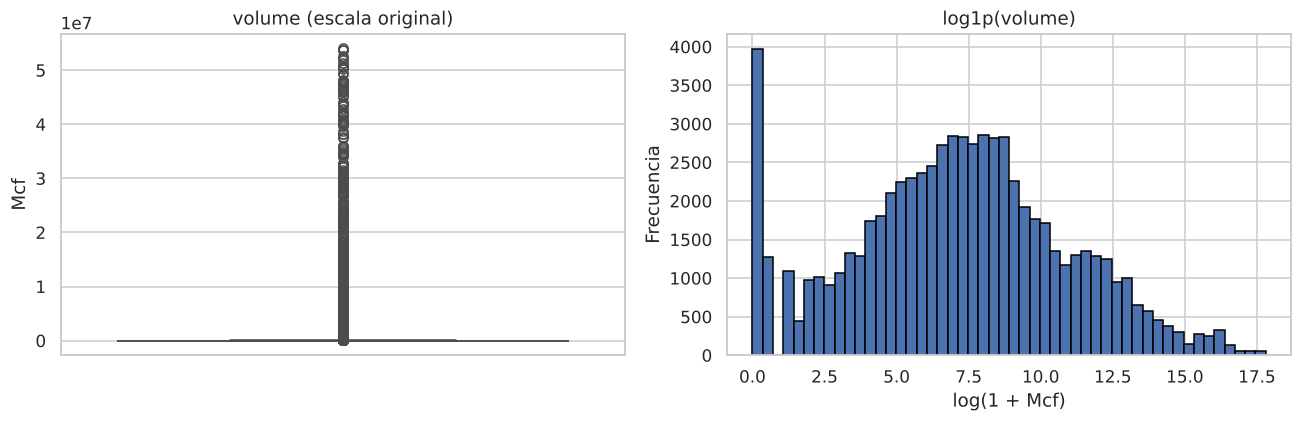

In [27]:
# Outliers de volume (único variable continua relevante)
q1 = gas_limpio['volume'].quantile(0.25)
q3 = gas_limpio['volume'].quantile(0.75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

gas_limpio['es_outlier_volume'] = (gas_limpio['volume'] < lim_inf) | (gas_limpio['volume'] > lim_sup)

print(f'Outliers: {gas_limpio["es_outlier_volume"].sum():,} '
      f'({gas_limpio["es_outlier_volume"].mean():.2%})')

# Distribución de outliers por categoría de disposición
print(pd.crosstab(gas_limpio['categoria'], gas_limpio['es_outlier_volume'], normalize='index').round(4))

# Gráficos: boxplot y histograma en escala log1p
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(y=gas_limpio['volume'], ax=axes[0], color='#55A868')
axes[0].set_title('volume (escala original)')
axes[0].set_ylabel('Mcf')

axes[1].hist(np.log1p(gas_limpio['volume']), bins=50, color='#4C72B0', edgecolor='black')
axes[1].set_title('log1p(volume)')
axes[1].set_xlabel('log(1 + Mcf)')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

#### Interpretación

- IQR marca 12805 valores por encima del UP de 34117.375 como posibles outliers. El LB no importa porque no tenemos valores negativos en vol_pos.

El IQR utiliza un criterio más amplio, y probablemente esto se deba a que tenemos mucho sesgo en 'vol_pos', muchos valores pequeños y algunos muy grandes.


Un outlier no es necesariamente un error, por lo que no deberíamos de eliminar estos registros automáticamente, ya que podrían ser volúmenes reales y quitarlos afectaría a nuestro análisis del venteo y la quema de gas. Hay que investigar más, y decidir si conservar los datos en caso de que el contexto lo amerite.

Podemos interpretar:

- De las 12805 filas marcadas, la mayoría son de venta: 10594 (más del 80%). Hay 1948 de quema y 263 de venteo.
- El máximo es mucho mayor para venta que para quema o venteo, por eso la cola tan alta de los gráficos y del IQR.
- Solo estamos viendo los valores mayores a 34117.375 del UB del IQR en vol_pos, no tenemos prueba de que hayan errores, pueden ser registros válidos de gran volumen.

### 3.7 - Encoding

In [28]:

UMBRAL_REGISTROS = 1500 #Lo colocamos para que cada estado onshore tenga suficientes observaciones
#para dar un coeficiente estable. Esto lo verificamos comprobando varios tipos de valores

ETIQ_OTROS = 'Otros estados'
ETIQ_INDIGENA = 'Tierra indígena (sin estado)'

# Estados onshore que no son tierra indígena
es_estado_onshore = (gas_limpio['land_category'].eq('Onshore')
                     & gas_limpio['land_class'].ne('Native American'))

#Selecciono las filas de la mascara y cuenta los registros que hay por estado
conteo_estados = gas_limpio.loc[es_estado_onshore, 'state'].value_counts()
#Filtramos los conteo y me quedo con aquellos que tengan al menos de 1500 registros y devuelve el nombre
estados_conservados = conteo_estados[conteo_estados >= UMBRAL_REGISTROS].index


In [29]:
#Construyo "ubicacion"
gas_limpio['ubicacion'] = np.select(
    [gas_limpio['land_category'].eq('Offshore'),
     gas_limpio['land_class'].eq('Native American'),
     es_estado_onshore & gas_limpio['state'].isin(estados_conservados)],
    [gas_limpio['offshore_region'], ETIQ_INDIGENA, gas_limpio['state']],
    default=ETIQ_OTROS
)
#Si el registro es offshore, toma ese
#Si es tierra indigena toma la etiqueta tierra indigena
#Si es onshore y no indigena toma el estaod conservado
#si no cumple ninguna toma etiq_otros

#Con el asster detenemos si la condicion es falsa y en la segunda fila comprobamos que no se duplico filas
assert gas_limpio['ubicacion'].notna().all(), 'Quedan valores sin ubicación'
assert len(gas_limpio) == 68964, 'Cambió el número de filas'

print('Estados conservados:', len(estados_conservados))
print('Estados agrupados en Otros:', sorted(conteo_estados[conteo_estados < UMBRAL_REGISTROS].index))
print(gas_limpio['ubicacion'].nunique(), 'niveles de ubicación')


Estados conservados: 11
Estados agrupados en Otros: ['AK', 'AL', 'ID', 'IL', 'KS', 'KY', 'MI', 'MS', 'NV', 'NY', 'OH', 'PA', 'SD', 'VA', 'WV']
16 niveles de ubicación


### 3.8 - Cambio de unidad de análisis: ubicación × mes

Cada renglón es un registro administrativo, no un pozo ni una instalación. Un operador puede tener muchos renglones de venta grandes y varios de venteo mínimo; contar renglones trata a todos igual, lo cual es un problema. La **solución** es agrupar por `ubicación` y mes, sumar el volumen total y el volumen perdido tanto por venteo y quema, y calcular:

- **tasa de pérdida** = volumen perdido / volumen total, donde volumen total = (venta + venteo + quema).
- **alta_perdida** = 1 si la tasa supera el umbral de negocio (10 %), 0 en otro caso.

La agrupación se hace sobre `gas_limpio`, después de construir `ubicacion`.

In [30]:
# Regla: pérdida significativa si la tasa supera el 10 % del volumen del mes
UMBRAL_TASA = 0.10

# Volumen perdido por renglón (venteo + quema). Venta queda en 0.
gas_limpio['vol_perdida'] = gas_limpio['vol_pos'] * gas_limpio['perdida']

#Agrupo por ubicacion y fecha de produccion y creo 4 columnas que resumen eso
agregado = (
    gas_limpio.groupby(['ubicacion', 'production_date'])
    .agg(vol_total=('vol_pos', 'sum'),
         vol_perdida=('vol_perdida', 'sum'),
         season=('season', 'first'),
         registros=('vol_pos', 'size'))
    .reset_index()
)

# La tasa no está definida si no hay volumen: se descartan esas celdas
agregado = agregado[agregado['vol_total'] > 0].copy()

#Calculo 1: Proporcion 
agregado['tasa_perdida'] = agregado['vol_perdida'] / agregado['vol_total']

#Calculo 2: alta perdida = 1 si la tasa de perdida es mayor al umbral, 0 en caso contrario
agregado['alta_perdida'] = (agregado['tasa_perdida'] > UMBRAL_TASA).astype(int)

agregado['año'] = agregado['production_date'].dt.year

# Orden temporal: necesario para TimeSeriesSplit y para el corte 2015-2023 / 2024-2025
agregado = agregado.sort_values('production_date').reset_index(drop=True)

print(f"Celdas ubicación × mes: {len(agregado):,}")
print(f"Ubicaciones: {agregado['ubicacion'].nunique()} | Meses: {agregado['production_date'].nunique()}")
print(f"Proporción alta_perdida (tasa > {UMBRAL_TASA:.0%}): {agregado['alta_perdida'].mean():.3f}")
print(f"Celdas con tasa = 0: {(agregado['tasa_perdida'] == 0).sum():,} | "
      f"tasa media: {agregado['tasa_perdida'].mean():.3f}")
print(f"Volumen perdido cubierto por celdas con alta_perdida = 1: "
      f"{agregado.loc[agregado['alta_perdida'] == 1, 'vol_perdida'].sum() / agregado['vol_perdida'].sum():.1%}")

Celdas ubicación × mes: 2,000
Ubicaciones: 16 | Meses: 125
Proporción alta_perdida (tasa > 10%): 0.216
Celdas con tasa = 0: 55 | tasa media: 0.134
Volumen perdido cubierto por celdas con alta_perdida = 1: 42.5%


**Verificación de separación.** Si una ubicación tiene todas sus celdas en 0, o todas en 1, el modelo no puede distinguirla por su tasa y el coeficiente de regresión logística se vuelve inestable. Esperamos que ocurra en algunas ubicaciones (ND siempre supera el umbral y WY nunca). Lo mostramos como un hallazgo sobre la ubicación misma.

In [31]:
sep = (agregado.groupby('ubicacion')
       .agg(celdas=('alta_perdida', 'size'),
            positivas=('alta_perdida', 'sum'),
            proporcion_alta=('alta_perdida', 'mean'),
            tasa_media=('tasa_perdida', 'mean'))
       .sort_values('proporcion_alta'))
sep['separacion_perfecta'] = sep['proporcion_alta'].isin([0, 1])
print(sep.round(3).to_string())

                              celdas  positivas  proporcion_alta  tasa_media  separacion_perfecta
ubicacion                                                                                        
AR                               125          0           0.0000      0.0000                 True
CO                               125          0           0.0000      0.0010                 True
LA                               125          0           0.0000      0.0020                 True
MT                               125          0           0.0000      0.0400                 True
OK                               125          0           0.0000      0.0010                 True
TX                               125          0           0.0000      0.0030                 True
WY                               125          0           0.0000      0.0120                 True
UT                               125          0           0.0000      0.0050                 True
CA                  

### 3.9 - Predictores, referencia y codificación

**Predictores:** `ubicacion` y `season`.

**Por qué no entra `año` (decisión del feedback 2):** si el año es un número, la regresión lineal extiende la tendencia 2015–2023 hacia 2024–2025 y el resultado depende del modelo elegido. Además, 2025 es un año parcial (enero–mayo). La pregunta es si la asociación con ubicación y estación se sostiene en años no vistos.

**Referencia:** `WY` e `Invierno`. Elegimos WY porque nunca supera el umbral; así los coeficientes de las demás ubicaciones se leen como "más o menos probable que WY".


In [32]:
PREDICTORES_CAT = ['ubicacion', 'season']
OBJETIVO = 'alta_perdida'
REFERENCIA = {'ubicacion': 'WY', 'season': 'Invierno'}

assert REFERENCIA['ubicacion'] in agregado['ubicacion'].unique(), 'Referencia de ubicación inexistente'

def con_referencia(serie, ref):
    """La referencia va primero: OneHotEncoder(drop='first') elimina ese nivel."""
    return [ref] + [n for n in sorted(serie.unique()) if n != ref]

categorias = [
    con_referencia(agregado['ubicacion'], REFERENCIA['ubicacion']),
    con_referencia(agregado['season'], REFERENCIA['season']),
]

# Codificador para modelos lineales (sin columna de referencia)
codificador = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(categories=categorias, drop='first',
                                 handle_unknown='ignore', sparse_output=False), PREDICTORES_CAT)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

# Codificador para árboles (conserva todas las columnas)
codificador_rf = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(categories=categorias, handle_unknown='ignore',
                                 sparse_output=False), PREDICTORES_CAT)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

X_all = agregado[PREDICTORES_CAT]
X_cod = codificador.fit_transform(X_all)
rango = np.linalg.matrix_rank(np.column_stack([np.ones(len(X_cod)), X_cod]))
print('Dimensiones X codificada:', X_cod.shape)
print('Rango con intercepto:', rango, '| Esperado sin dependencias:', X_cod.shape[1] + 1)
print(list(codificador.get_feature_names_out()))

Dimensiones X codificada: (2000, 18)
Rango con intercepto: 19 | Esperado sin dependencias: 19
['ubicacion_AR', 'ubicacion_CA', 'ubicacion_CO', 'ubicacion_LA', 'ubicacion_MT', 'ubicacion_ND', 'ubicacion_NM', 'ubicacion_OK', 'ubicacion_Offshore Alaska', 'ubicacion_Offshore Gulf', 'ubicacion_Offshore Pacific', 'ubicacion_Otros estados', 'ubicacion_TX', 'ubicacion_Tierra indígena (sin estado)', 'ubicacion_UT', 'season_Otoño', 'season_Primavera', 'season_Verano']


### 3.10 - Partición temporal

**Entrenamiento**: meses hasta diciembre de 2023. 

**Verificación**: enero de 2024 hasta mayo de 2025.

Con una partición aleatoria, celdas de la misma ubicación en meses vecinos podían caer en entrenamiento y prueba a la vez, lo que infla las métricas. Con el corte temporal, la prueba solo contiene meses posteriores a los del entrenamiento.

In [33]:
CORTE_TEMPORAL = 2023

train = agregado[agregado['año'] <= CORTE_TEMPORAL].copy()
test = agregado[agregado['año'] > CORTE_TEMPORAL].copy()

X_train, y_train = train[PREDICTORES_CAT], train[OBJETIVO]
X_test, y_test = test[PREDICTORES_CAT], test[OBJETIVO]

print(f"Entrenamiento: {len(train):,} celdas ({train['production_date'].min():%Y-%m} a {train['production_date'].max():%Y-%m})")
print(f"Verificación:  {len(test):,} celdas ({test['production_date'].min():%Y-%m} a {test['production_date'].max():%Y-%m})")
print(f"Proporción alta_perdida  train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")
print('\nProporción de alta_perdida por año:')
print(agregado.groupby('año')['alta_perdida'].agg(['size', 'mean']).round(3).to_string())

Entrenamiento: 1,728 celdas (2015-01 a 2023-12)
Verificación:  272 celdas (2024-01 a 2025-05)
Proporción alta_perdida  train: 0.219 | test: 0.195

Proporción de alta_perdida por año:
      size   mean
año              
2015   192 0.2290
2016   192 0.1930
2017   192 0.2340
2018   192 0.2550
2019   192 0.2500
2020   192 0.2500
2021   192 0.1880
2022   192 0.1880
2023   192 0.1880
2024   192 0.1930
2025    80 0.2000


## Parte 4 - Análisis de algoritmos (con partición temporal)

**Validación cruzada**: `TimeSeriesSplit`. Cada partición entrena con el pasado y valida sobre el bloque siguiente, así que nunca se usa el futuro para entrenar. Las métricas de validación cruzada se usan para elegir el modelo; la prueba (2024–2025) se usa una sola vez al final.

### 4.1 - Algoritmos

In [34]:
cv = TimeSeriesSplit(n_splits=5)

scoring = {
    'accuracy': 'accuracy',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
    'recall': 'recall',
}

# Línea base: probabilidad igual a la proporción de la clase en entrenamiento

#Dummy
baseline = Pipeline([
    ('encoding', clone(codificador)),
    ('clf', DummyClassifier(strategy='prior'))
])

#Regresion Logistica
modelo_lr = Pipeline([
    ('encoding', clone(codificador)),
    ('clf', LogisticRegression(max_iter=1000))
])

#Random Forest
modelo_rf = Pipeline([
    ('encoding', clone(codificador_rf)),
    ('clf', RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=20,      # con ~1.000 celdas, 50 sería demasiado para algunas hojas
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

def combinar_celda(df):
    return (df['ubicacion'].astype(str) + ' | ' + df['season'].astype(str)).to_frame('celda')

# Techo con estos predictores: una tasa independiente por cada ubicación × estación
modelo_celda = Pipeline([
    ('celda', FunctionTransformer(combinar_celda)),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ('clf', LogisticRegression(max_iter=1000))
])

modelos_cv = {
    'Dummy (línea base)': baseline,
    'Regresión Logística': modelo_lr,
    'Random Forest': modelo_rf,
    'Tasa por celda (techo)': modelo_celda,
}

filas = {}
for nombre, modelo in modelos_cv.items():
    res = cross_validate(modelo, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    fila = {m: res[f'test_{m}'].mean() for m in scoring}
    fila['roc_auc_desvio'] = res['test_roc_auc'].std()
    fila['roc_auc_train'] = res['train_roc_auc'].mean()
    filas[nombre] = fila

resumen_cv = pd.DataFrame(filas).T
print('Validación cruzada temporal (5 particiones, solo entrenamiento 2015–2023)')
print(resumen_cv.round(4).to_string())

Validación cruzada temporal (5 particiones, solo entrenamiento 2015–2023)
                        accuracy  roc_auc  pr_auc  recall  roc_auc_desvio  roc_auc_train
Dummy (línea base)        0.7806   0.5000  0.2194  0.0000          0.0000         0.5000
Regresión Logística       0.9472   0.9911  0.9774  0.9027          0.0075         0.9896
Random Forest             0.9153   0.8941  0.8299  0.7424          0.1953         0.8976
Tasa por celda (techo)    0.9444   0.9824  0.9620  0.8396          0.0196         0.9909


**Explicación de la validación cruzada temporal**

Comparamos cuatro modelos con `TimeSeriesSplit` en 5 particiones, usando solo 2015–2023. En cada partición, el modelo entrena con los meses anteriores y evalúa sobre el bloque siguiente. La tabla muestra el promedio de las 5 particiones. `roc_auc_desvio` indica cuánto varía el ROC-AUC entre ellas, y `roc_auc_train` es el ROC-AUC sobre los datos de entrenamiento de cada partición.

El motivo es que queremos estimar cómo se comportará cada modelo con meses que todavía no vio, sin usar 2024–2025. Esta comparación sirve para elegir qué modelo seguir; la evaluación final se hace en la sección 5.

**Lectura de las métricas:**
- **Exactitud:** porcentaje de celdas bien clasificadas. Engaña cuando una clase domina: el Dummy acierta el 78 % sin predecir nunca alta pérdida.
- **ROC-AUC:** probabilidad de que una celda de alta pérdida reciba un puntaje mayor que una celda normal. Vale 0,5 con predicciones al azar y 1 con separación perfecta.
- **PR-AUC:** qué tan bien se separa la clase de alta pérdida. Su valor de referencia es la proporción de positivos (alrededor de 0,22), que es el resultado de un clasificador al azar.
- **Recall:** de las celdas de alta pérdida reales, qué fracción detecta el modelo.
- **Desvío del ROC-AUC:** variación entre particiones. Un desvío alto indica que el resultado depende de la partición usada.
- **ROC-AUC de entrenamiento frente a validación:** una diferencia grande indicaría sobreajuste.

**Conclusiones:**
- **Dummy (línea base):** ROC-AUC de 0,500 y PR-AUC de 0,219. Es el piso de comparación: su recall es 0, porque nunca predice alta pérdida.
- **Regresión logística:** mejor resultado en ROC-AUC (0,991), PR-AUC (0,977) y recall (0,903), con desvío bajo (0,008). Es estable entre particiones.
- **Random Forest:** ROC-AUC de 0,894, PR-AUC de 0,830 y recall de 0,742, con un desvío muy alto (0,195). Su rendimiento depende mucho de la partición, así que su promedio no es confiable. Las particiones tempranas tienen pocos meses de entrenamiento, y eso afecta más a un modelo de árboles que a uno lineal.
- **Tasa por celda (techo):** ROC-AUC de 0,983, algo por debajo de la regresión logística. Un modelo con una tasa independiente para cada combinación ubicación × estación no mejora frente al modelo aditivo, así que no hace falta una interacción entre ubicación y estación para explicar los datos.
- **Sobreajuste:** la regresión logística tiene ROC-AUC de 0,990 en entrenamiento y 0,991 en validación. No hay señal de sobreajuste. En la tasa por celda la diferencia es algo mayor (0,991 frente a 0,983), pero sigue siendo pequeña.

**Ajuste de C (regularización de la regresión logística).** C controla cuánto pueden crecer los coeficientes. Lo elegimos por validación cruzada temporal, usando solo entrenamiento.

In [35]:
param_grid = {'clf__C': [0.01, 0.1, 1, 10, 100]}

busqueda_lr = GridSearchCV(
    modelo_lr,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    refit=True,
    n_jobs=-1,
    return_train_score=True
)
busqueda_lr.fit(X_train, y_train)

mejor_C = busqueda_lr.best_params_['clf__C']
print('Mejor C:', mejor_C)
print(f'Mejor ROC-AUC (validación temporal): {busqueda_lr.best_score_:.4f}')

resultados_C = pd.DataFrame(busqueda_lr.cv_results_)[
    ['param_clf__C', 'mean_test_score', 'std_test_score', 'mean_train_score']
].rename(columns={'param_clf__C': 'C', 'mean_test_score': 'roc_auc_val',
                  'std_test_score': 'desvio', 'mean_train_score': 'roc_auc_train'})
print(resultados_C.round(4).to_string(index=False))

lr_final = busqueda_lr.best_estimator_

Mejor C: 1
Mejor ROC-AUC (validación temporal): 0.9911
       C  roc_auc_val  desvio  roc_auc_train
  0.0100       0.9902  0.0089         0.9870
  0.1000       0.9903  0.0086         0.9880
  1.0000       0.9911  0.0075         0.9896
 10.0000       0.9904  0.0084         0.9901
100.0000       0.9897  0.0092         0.9902


**Explicación del ajuste de C (regularización)**

Probamos cinco valores de `C` en la regresión logística (0,01, 0,1, 1, 10 y 100) con `GridSearchCV` y la misma validación temporal de 5 particiones. `C` controla cuánto pueden crecer los coeficientes: valores altos los dejan crecer más (menos regularización) y valores bajos los penalizan. El criterio de elección fue el ROC-AUC de validación. Después de elegir, el modelo se reentrenó con todo 2015–2023 (`refit=True`)

La regularización es el control habitual contra el sobreajuste. Probar varios valores permite comprobar si el resultado depende de esa elección.

**Lectura de la tabla:**
- `roc_auc_val`: ROC-AUC promedio en validación para cada `C`.
- `desvio`: variación entre las 5 particiones.
- `roc_auc_train`: ROC-AUC en entrenamiento. Si crece mucho más que la validación, hay sobreajuste.

**Conclusiones:**
- El mejor valor es `C = 1`, con ROC-AUC de validación de 0,991.
- La diferencia entre los cinco valores es de 0,0014 (de 0,9897 a 0,9911). Es menor que el desvío entre particiones (cerca de 0,008), así que no hay un `C` claramente superior.
- El ROC-AUC de entrenamiento sube levemente con `C`, pero la distancia con validación se mantiene chica en todos los casos: no hay señal de sobreajuste.
- Con pocas variables codificadas, la regularización casi no restringe el modelo. Por eso el valor de `C` tiene poco efecto sobre el resultado.

### 4.2 - Regresión como comparación

Para comparar con la clasificación sin perder la lógica del umbral, el modelo de regresión predice la **tasa de pérdida** (un número continuo entre 0 y 1). Después se aplica el mismo umbral del 10 %: si la tasa predicha supera 0,10, la celda se clasifica como alta pérdida.

Así, ambos enfoques responden la misma pregunta y pueden compararse en las mismas métricas de clasificación.

In [36]:
y_train_tasa = train['tasa_perdida']
y_test_tasa = test['tasa_perdida']

modelo_reg = Pipeline([
    ('encoding', clone(codificador)),
    ('reg', Ridge(alpha=1.0))
])

res_reg = cross_validate(modelo_reg, X_train, y_train_tasa, cv=cv,
                         scoring=['r2', 'neg_mean_absolute_error'])
print('Regresión sobre tasa (validación cruzada temporal):')
print(f"  R² medio: {res_reg['test_r2'].mean():.4f} (desvío {res_reg['test_r2'].std():.4f})")
print(f"  MAE medio: {-res_reg['test_neg_mean_absolute_error'].mean():.4f}")

Regresión sobre tasa (validación cruzada temporal):
  R² medio: 0.9382 (desvío 0.0280)
  MAE medio: 0.0329


**Explicación de la regresión sobre la tasa de pérdida**

En lugar de clasificar, entrenamos un modelo Ridge que predice la `tasa_perdida` de cada celda, un número entre 0 y 1. Usamos el mismo codificador (ubicación y estación) y la misma validación temporal de 5 particiones que en la sección 4.1, solo con datos de 2015–2023. Medimos dos métricas: R² (qué parte de la variación de la tasa explica el modelo) y MAE (error absoluto medio, en puntos de tasa).

La tasa es la variable de la que sale la etiqueta `alta_perdida`. Predecirla permite aplicar el mismo umbral del 10 % y comparar después la regresión con la clasificación. En esta sección todavía no se comparan clasificaciones: esa comparación se hace en la sección 5, sobre 2024–2025.

**Resultados (validación cruzada temporal):**
- R² medio: 0,938 (desvío 0,028). La tasa predicha explica cerca del 94 % de la variación de la tasa real.
- MAE medio: 0,033, es decir, unos 3,3 puntos porcentuales de error medio por celda.

**Lectura de los resultados:**
- Buena parte de la variación de la tasa viene de las diferencias entre ubicaciones (por ejemplo, ND y WY). Por eso un R² alto no garantiza precisión dentro de cada ubicación.
- El MAE se interpreta en relación con la tasa típica del periodo, que se reporta en la sección 5.
- El desvío del R² entre particiones indica cuánto depende el resultado del periodo usado para validar.

**Limitaciones:** Ridge es un modelo lineal y puede predecir valores fuera del intervalo [0, 1]. Esas predicciones se mantienen tal cual para aplicar el umbral en la sección 5.

# Parte 5 - Evaluación del modelo final

Se ajustan los modelos con todo el entrenamiento (2015–2023) y se evalúan **una sola vez** en 2024–2025.

## 5.1 - Modelo

In [37]:
#Calculo de métricas de clasificación y regresión sobre el conjunto de verificación (2024–2025)
def metricas_clasificacion(y_real, score, umbral=0.5):
    pred = (score >= umbral).astype(int)
    return {
        'ROC-AUC': roc_auc_score(y_real, score),
        'PR-AUC': average_precision_score(y_real, score),
        'Exactitud': accuracy_score(y_real, pred),
        'Recall (alta)': recall_score(y_real, pred, zero_division=0),
        'Precisión (alta)': precision_score(y_real, pred, zero_division=0),
    }

#Reentrenamos los modelos con clone para no arastrar ajustes previos
ajustados = {
    'Dummy (línea base)': clone(baseline).fit(X_train, y_train),
    'Regresión Logística': clone(lr_final).fit(X_train, y_train),
    'Random Forest': clone(modelo_rf).fit(X_train, y_train),
    'Tasa por celda (techo)': clone(modelo_celda).fit(X_train, y_train),
}

filas_test = {}
probs = {}
for nombre, m in ajustados.items():
    p = m.predict_proba(X_test)[:, 1]
    probs[nombre] = p
    filas_test[nombre] = metricas_clasificacion(y_test, p)

# Regresión sobre tasa, clasificada con el mismo umbral del 10 %
modelo_reg_final = clone(modelo_reg).fit(X_train, y_train_tasa)
tasa_pred = modelo_reg_final.predict(X_test)
probs['Regresión sobre tasa'] = tasa_pred
filas_test['Regresión sobre tasa'] = metricas_clasificacion(y_test, tasa_pred, umbral=UMBRAL_TASA)
filas_test['Regresión sobre tasa']['R² (tasa)'] = r2_score(y_test_tasa, tasa_pred)
filas_test['Regresión sobre tasa']['MAE (tasa)'] = mean_absolute_error(y_test_tasa, tasa_pred)

tabla_test = pd.DataFrame(filas_test).T
print('Resultados en verificación 2024–2025 (una sola vez):')
print(tabla_test.round(4).to_string())
print(f"\nProporción alta_perdida en verificación: {y_test.mean():.4f}")

Resultados en verificación 2024–2025 (una sola vez):
                        ROC-AUC  PR-AUC  Exactitud  Recall (alta)  Precisión (alta)  R² (tasa)  MAE (tasa)
Dummy (línea base)       0.5000  0.1949     0.8051         0.0000            0.0000        NaN         NaN
Regresión Logística      0.9807  0.9746     0.9926         0.9623            1.0000        NaN         NaN
Random Forest            0.9810  0.9764     0.9926         0.9623            1.0000        NaN         NaN
Tasa por celda (techo)   0.9856  0.9767     0.9926         0.9623            1.0000        NaN         NaN
Regresión sobre tasa     0.9886  0.9799     0.9301         0.9623            0.7500     0.9193      0.0343

Proporción alta_perdida en verificación: 0.1949


**Explicación evaluación final en 2024–2025**

Entrenamos cada modelo con todo 2015–2023 y lo evaluamos una sola vez en 2024 a mayo de 2025: 272 celdas, de las cuales 53 son de alta pérdida (19,5 %). Para los modelos de probabilidad usamos el umbral 0,5. Para la regresión sobre la tasa usamos el umbral de negocio del 10 %, porque su salida es una tasa y no una probabilidad.

La verificación sirve para estimar el desempeño con datos nuevos. El modelo principal se eligió con la validación cruzada de la sección 4, no con estos resultados.

**Lectura de la tabla:**
- ROC-AUC y PR-AUC miden qué tan bien se ordenan las celdas y no dependen del umbral.
- Exactitud, recall y precisión dependen del umbral elegido, por eso no son directamente comparables entre la logística y la regresión sobre la tasa.
- Con 53 casos positivos, diferencias de 0,01 o menos en ROC-AUC no son concluyentes (ver sección 5.3).

**Resultados:**
- Todos los modelos con información de ubicación superan 0,98 de ROC-AUC. Las diferencias entre ellos (0,981 a 0,989) son pequeñas.
- La regresión sobre la tasa tiene el ROC-AUC más alto (0,989), pero su precisión baja a 0,75: de las 68 celdas que marca como alta, 17 son normales (falsas alarmas). Por eso su exactitud es menor (0,930).
- La regresión logística tiene precisión 1,00 y recall 0,96: no marca falsas alarmas, pero deja pasar 2 de las 53 celdas de alta pérdida.
- Random Forest y tasa por celda obtienen resultados muy similares a la logística y no la superan en recall ni precisión.

**Conclusión:** la diferencia entre modelos es pequeña y no alcanza para elegir uno con confianza a partir de 2024–2025. La regresión logística se mantiene como modelo principal porque fue el de mejor desempeño en validación cruzada (sección 4). En 2024–2025 no genera falsas alarmas con el umbral de 0,5, pero ese resultado depende del umbral elegido.

Reporte de clasificación – Regresión Logística (umbral 0,5):
              precision    recall  f1-score   support

      Normal     0.9910    1.0000    0.9955       219
Alta pérdida     1.0000    0.9623    0.9808        53

    accuracy                         0.9926       272
   macro avg     0.9955    0.9811    0.9881       272
weighted avg     0.9927    0.9926    0.9926       272

Matriz de confusión (filas = real, columnas = predicho):
[[219   0]
 [  2  51]]


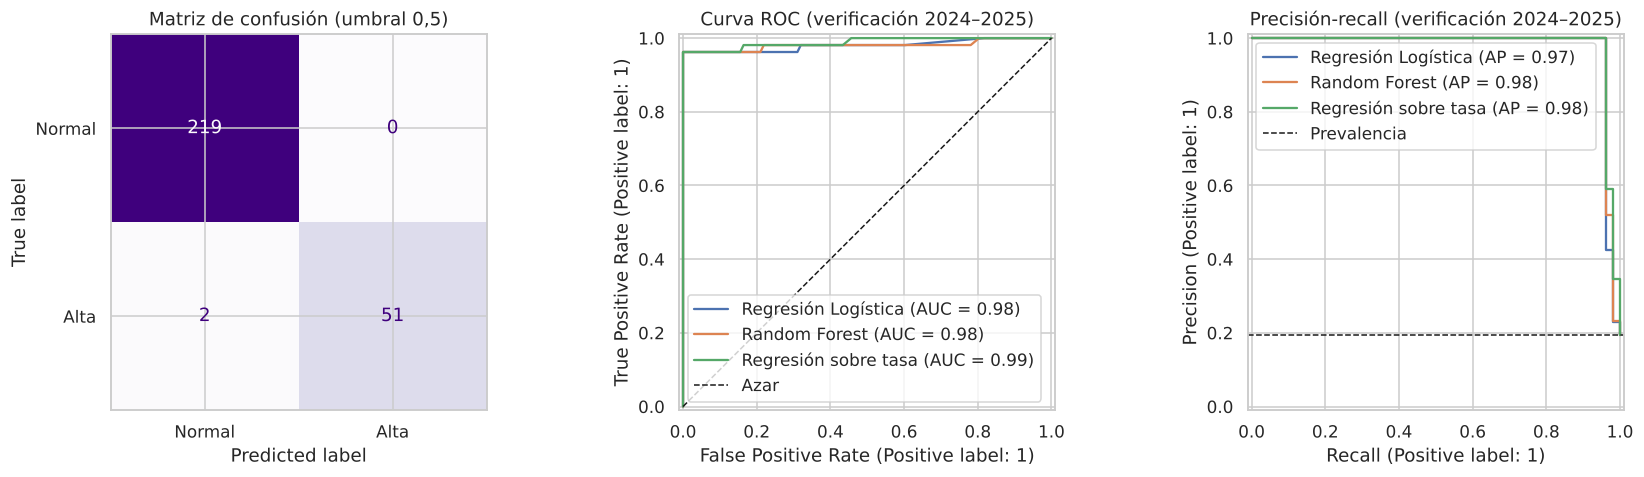

In [38]:
# 1) Predicciones calculadas una sola vez
p_lr = probs['Regresión Logística']
pred_lr = (p_lr >= 0.5).astype(int)
cm_lr = confusion_matrix(y_test, pred_lr)

print('Reporte de clasificación – Regresión Logística (umbral 0,5):')
print(classification_report(y_test, pred_lr, target_names=['Normal', 'Alta pérdida'],
                            digits=4, zero_division=0))
print('Matriz de confusión (filas = real, columnas = predicho):')
print(cm_lr)

# 2) Una sola figura, un solo bucle sobre los modelos
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay(cm_lr, display_labels=['Normal', 'Alta']).plot(
    ax=axes[0], cmap='Purples', colorbar=False)
axes[0].set_title('Matriz de confusión (umbral 0,5)')

for nombre in ['Regresión Logística', 'Random Forest', 'Regresión sobre tasa']:
    RocCurveDisplay.from_predictions(y_test, probs[nombre], ax=axes[1], name=nombre)
    PrecisionRecallDisplay.from_predictions(y_test, probs[nombre], ax=axes[2], name=nombre)

axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Azar')
axes[1].set_title('Curva ROC (verificación 2024–2025)')
axes[1].legend()

axes[2].axhline(y_test.mean(), color='k', ls='--', lw=1, label='Prevalencia')
axes[2].set_title('Precisión-recall (verificación 2024–2025)')
axes[2].legend()

plt.tight_layout()
plt.show()

 celdas_entrenamiento  logloss_entrenamiento  logloss_verificacion
                  172                 0.1963                0.2674
                  345                 0.1640                0.1521
                  518                 0.1473                0.1255
                  691                 0.1388                0.1249
                  864                 0.1379                0.1302
                 1036                 0.1274                0.1345
                 1209                 0.1207                0.1319
                 1382                 0.1177                0.1175
                 1555                 0.1123                0.1067
                 1728                 0.1071                0.0987


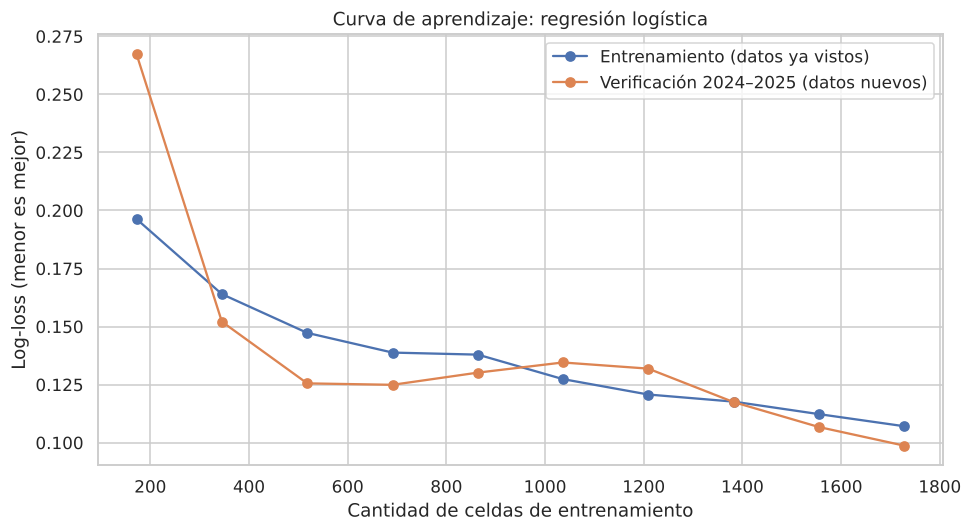

In [39]:
from sklearn.model_selection import learning_curve

# Un único pliegue: entrena con 2015–2023 y evalúa sobre 2024–2025.
# Los índices son posicionales, así que X_all debe quedar en el orden train → test.
X_all = pd.concat([X_train, X_test])
y_all = pd.concat([y_train, y_test])
n_tr = len(X_train)
cv_holdout = [(np.arange(n_tr), np.arange(n_tr, len(X_all)))]

# Tamaños de entrenamiento como fracción de 2015–2023 (10 puntos)
train_sizes = np.linspace(0.1, 1.0, 10)

# shuffle=False conserva el orden temporal: cada tamaño usa los primeros meses de 2015–2023
tamanos, train_scores, test_scores = learning_curve(
    clone(lr_final), X_all, y_all,
    cv=cv_holdout,
    train_sizes=train_sizes,
    scoring='neg_log_loss',
    shuffle=False,
    n_jobs=-1,
)

# scikit-learn devuelve neg_log_loss: se invierte el signo para que el eje Y sea log-loss
df_curva = pd.DataFrame({
    'celdas_entrenamiento': tamanos,
    'logloss_entrenamiento': -train_scores.mean(axis=1),
    'logloss_verificacion': -test_scores.mean(axis=1),
})
print(df_curva.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df_curva['celdas_entrenamiento'], df_curva['logloss_entrenamiento'],
        'o-', label='Entrenamiento (datos ya vistos)')
ax.plot(df_curva['celdas_entrenamiento'], df_curva['logloss_verificacion'],
        'o-', label='Verificación 2024–2025 (datos nuevos)')
ax.set_xlabel('Cantidad de celdas de entrenamiento')
ax.set_ylabel('Log-loss (menor es mejor)')
ax.set_title('Curva de aprendizaje: regresión logística')
ax.legend()
plt.tight_layout()
plt.show()

**Explicación de la curva de aprendizaje (log-loss)**

Medimos cómo cambia el error de la regresión logística a medida que aumenta la cantidad de celdas de entrenamiento. Usamos `learning_curve` con un único pliegue: entrena con los primeros meses de 2015–2023 y evalúa sobre 2024–2025. Las celdas se toman en orden temporal (`shuffle=False`), así que cada punto usa solo meses anteriores. El log-loss mide qué tan bien se ajustan las probabilidades a los resultados reales: cuanto más bajo, mejor.

La curva permite ver si el modelo generaliza (el error de verificación se acerca al de entrenamiento) y si más datos podrían mejorarlo (las curvas siguen bajando).

**Lectura de la tabla:**
- `logloss_entrenamiento`: error sobre las mismas celdas con las que se entrenó en cada punto.
- `logloss_verificacion`: error sobre 2024–2025, datos que el modelo nunca vio.

**Resultados:**
- Ambas curvas bajan al aumentar la cantidad de datos de entrenamiento, lo que indica que el modelo aprende más a medida que ve más celdas.
- Al principio, el error sobre datos nuevos es mayor que sobre los datos de entrenamiento, porque con poca historia el modelo no conoce bien todas las ubicaciones.
- Hacia el final, el error sobre 2024–2025 queda por debajo del de entrenamiento. No indica sobreajuste. Es coherente con que ese periodo tenga menos casos de alta pérdida y sea más fácil de predecir.
- La curva de verificación sube levemente en un tramo intermedio. Con pocos casos positivos en 2024–2025, esa variación puede ser ruido.
- Ninguna curva llega a aplanarse, así que no sabemos si agregar más datos mejoraría el modelo..

**Conclusión:** no hay señal de sobreajuste, y el modelo generaliza a 2024–2025 con un error muy por debajo del de un modelo que predice siempre la prevalencia. Ninguna curva llegó a aplanarse, pero no hay datos de entrenamiento posteriores a 2023 para comprobar si más datos mejorarían el resultado.

Reporte de clasificación – Regresión Logística (umbral 0,5):
              precision    recall  f1-score   support

      Normal     0.9910    1.0000    0.9955       219
Alta pérdida     1.0000    0.9623    0.9808        53

    accuracy                         0.9926       272
   macro avg     0.9955    0.9811    0.9881       272
weighted avg     0.9927    0.9926    0.9926       272



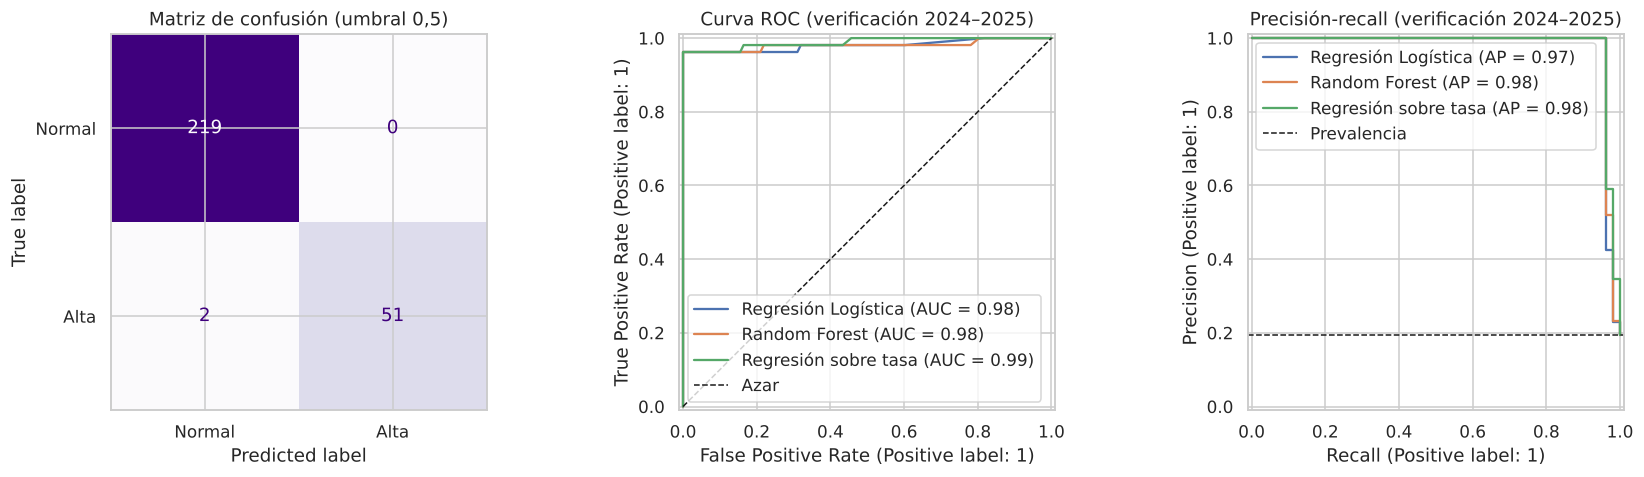

In [40]:

p_lr = probs['Regresión Logística']
pred_lr = (p_lr >= 0.5).astype(int)

print('Reporte de clasificación – Regresión Logística (umbral 0,5):')
print(classification_report(y_test, pred_lr, target_names=['Normal', 'Alta pérdida'], digits=4, zero_division=0))


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_lr),
                       display_labels=['Normal', 'Alta']).plot(ax=axes[0], cmap='Purples', colorbar=False)
axes[0].set_title('Matriz de confusión (umbral 0,5)')

for nombre in ['Regresión Logística', 'Random Forest', 'Regresión sobre tasa']:
    RocCurveDisplay.from_predictions(y_test, probs[nombre], ax=axes[1], name=nombre)
    PrecisionRecallDisplay.from_predictions(y_test, probs[nombre], ax=axes[2], name=nombre)
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Azar')
axes[1].set_title('Curva ROC (verificación 2024–2025)')
axes[1].legend()
axes[2].axhline(y_test.mean(), color='k', ls='--', lw=1, label='Prevalencia')
axes[2].set_title('Precisión-recall (verificación 2024–2025)')
axes[2].legend()
plt.tight_layout()
plt.show()


Evaluamos la regresión logística con umbral 0,5 sobre 2024–2025 y mostramos tres gráficos: la matriz de confusión, la curva ROC y la curva de precisión-recall. El reporte de clasificación resume precisión, recall y F1 por clase. Esta evaluación se hace una sola vez, con los modelos ya elegidos en la sección 4.

El reporte y la matriz muestran qué tipo de error comete el modelo, algo que una sola métrica no permite ver. Las curvas muestran el comportamiento del modelo en todos los umbrales posibles, no solo en 0,5.

**Lectura del reporte:**
- *Precisión:* de las celdas que el modelo marca como cierta clase, qué fracción realmente pertenece a ella.
- *Recall:* de las celdas que realmente pertenecen a una clase, qué fracción el modelo detecta.
- *F1-score:* promedio armónico entre precisión y recall.
- *Support:* cantidad de celdas reales de cada clase en verificación.

**Lectura de la matriz de confusión:** las filas son la clase real y las columnas la predicha. La diagonal corresponde a aciertos. Los errores son de dos tipos: falsos positivos (celda normal marcada como alta) y falsos negativos (celda de alta pérdida no detectada).

**Lectura de las curvas:**
- *ROC:* muestra la tasa de detección frente a la tasa de falsas alarmas al variar el umbral. Cuanto más arriba y a la izquierda, mejor. La línea punteada es el azar.
- *Precisión-recall:* muestra cómo cambia la precisión al aumentar el recall. La línea punteada horizontal es la prevalencia de la clase alta (alrededor de 0,19 en este periodo): un clasificador al azar tendría esa precisión.

**Resultados:**
- *Clase normal:* recall perfecto. Ninguna celda normal fue marcada como alta.
- *Clase alta pérdida:* precisión perfecta. Toda celda marcada como alta lo era.
- *Errores:* el modelo deja pasar 2 de las 53 celdas de alta pérdida (falsos negativos). No hay falsos positivos con el umbral 0,5.
- En la curva ROC, las tres regresiones quedan muy cerca del ángulo superior izquierdo, y las diferencias entre ellas son pequeñas.
- En la curva de precisión-recall, la logística y las otras dos mantienen precisión alta hasta recall cercano a 0,96, y después la precisión cae de forma brusca. Eso refleja las dos celdas que no detecta y la cantidad limitada de positivos.

**Conclusión:** la logística casi no se equivoca en la clase normal y acierta en casi todas las celdas de alta pérdida. Su único error relevante son las dos celdas de alta pérdida no detectadas. Las curvas ROC y precisión-recall son muy similares entre los tres modelos, lo que coincide con lo observado en la tabla de la sección 5.

## 5.2 - Intervalo de confianza por bootstrap de bloques mensuales

Las celdas de un mismo mes están correlacionadas entre ubicaciones, así que el remuestreo se hace por **meses completos**, no por celda.

In [41]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
p_arr = np.asarray(probs['Regresión Logística'])

meses = test['production_date'].unique()
idx_por_mes = {m: np.where(test['production_date'].values == m)[0] for m in meses}

boot_auc, boot_pr = [], []
for _ in range(1000):
    muestra = rng.choice(meses, size=len(meses), replace=True)
    idx = np.concatenate([idx_por_mes[m] for m in muestra])
    if len(np.unique(y_arr[idx])) < 2:
        continue
    boot_auc.append(roc_auc_score(y_arr[idx], p_arr[idx]))
    boot_pr.append(average_precision_score(y_arr[idx], p_arr[idx]))

ic_auc = np.percentile(boot_auc, [2.5, 97.5])
ic_pr = np.percentile(boot_pr, [2.5, 97.5])
print(f"ROC-AUC verificación: {tabla_test.loc['Regresión Logística', 'ROC-AUC']:.4f}  "
      f"IC 95 %: [{ic_auc[0]:.4f}, {ic_auc[1]:.4f}]")
print(f"PR-AUC verificación:  {tabla_test.loc['Regresión Logística', 'PR-AUC']:.4f}  "
      f"IC 95 %: [{ic_pr[0]:.4f}, {ic_pr[1]:.4f}]")
print(f"Remuestras válidas: {len(boot_auc)} de 1000")

ROC-AUC verificación: 0.9807  IC 95 %: [0.9543, 1.0000]
PR-AUC verificación:  0.9746  IC 95 %: [0.9425, 1.0000]
Remuestras válidas: 1000 de 1000


**Explicación del intervalo de confianza por bootstrap de bloques mensuales**

Repetimos 1.000 veces la evaluación de la regresión logística, remuestreando con reemplazo los meses completos de verificación (2024 a mayo de 2025). En cada repetición calculamos ROC-AUC y PR-AUC, y con esas 1.000 estimaciones tomamos los percentiles 2,5 y 97,5 para formar un intervalo del 95 %.

Lo hicimos por meses porque las celdas de un mismo mes comparten las condiciones del periodo, así que no son independientes. Remuestrear celda por celda daría intervalos demasiado estrechos. Remuestrear meses completos respeta esa dependencia.

**Lectura de los resultados:**
- El intervalo indica el rango de valores razonablemente compatible con los datos. No es una garantía de que el valor real esté dentro.
- El límite superior llega a 1,000, que es el máximo posible. Eso indica que en muchas remuestras el modelo separa perfectamente las clases. Una metrica mas alta no aportaria informacion nueva
- El límite inferior (cerca de 0,95 en ambas métricas) es el valor más útil para estimar un desempeño conservador.

### 5.3 - Sensibilidad al umbral (5 %, 10 % y 15 %)

Repetimos la regresión logística con las mismas variables (ubicación y estación) y las mismas particiones, cambiando solo el umbral que define una celda de alta pérdida. Probamos 5 %, 10 % y 15 % de la tasa de pérdida.

El umbral del 10 % es una regla de negocio y no sale de los datos. Si el resultado cambia mucho con el umbral, el ROC-AUC de 0,98 de la sección 5 depende de esa regla elegida, y no es una propiedad robusta de la pérdida. Esta prueba mide cuánto depende.

**Lectura del cuadro:**
- *Positivos en verificación:* cuántas celdas de 2024–2025 superan ese umbral. Cuanto menos positivos, menos casos hay para evaluar.
- *ROC-AUC y PR-AUC:* qué tan bien el modelo separa las celdas de alta pérdida de las normales, con el umbral indicado. La interpretación de cada métrica está en la sección 4.

In [42]:
# Sensibilidad al umbral: mismo modelo y mismas variables, cambiando solo el umbral de la tasa
THRESHOLDS = [0.05, 0.10, 0.15]
threshold_rows = []

for umbral in THRESHOLDS:
    y_train_umbral = (train['tasa_perdida'] > umbral).astype(int)
    y_test_umbral = (test['tasa_perdida'] > umbral).astype(int)

    modelo_umbral = Pipeline([
        ('encoding', clone(codificador)),
        ('clf', LogisticRegression(C=1, max_iter=1000))
    ]).fit(X_train, y_train_umbral)

    p_umbral = modelo_umbral.predict_proba(X_test)[:, 1]
    threshold_rows.append({
        'Umbral': f'{umbral:.0%}',
        'Positivos en verificación': int(y_test_umbral.sum()),
        'Prevalencia en verificación': y_test_umbral.mean(),
        'ROC-AUC': roc_auc_score(y_test_umbral, p_umbral),
        'PR-AUC': average_precision_score(y_test_umbral, p_umbral),
    })

THRESHOLD_SENSITIVITY = pd.DataFrame(threshold_rows).set_index('Umbral')
print('Sensibilidad al umbral (regresión logística, verificación 2024–2025):')
print(THRESHOLD_SENSITIVITY.round(3).to_string())

Sensibilidad al umbral (regresión logística, verificación 2024–2025):
        Positivos en verificación  Prevalencia en verificación  ROC-AUC  PR-AUC
Umbral                                                                         
5%                             84                       0.3090   0.8830  0.8270
10%                            53                       0.1950   0.9810  0.9750
15%                            50                       0.1840   1.0000  0.9980


#### Resultados

| Umbral | Positivos en verificación | Prevalencia | ROC-AUC | PR-AUC |
|---|---|---|---|---|
| 5 % | 84 | 0,309 | 0,883 | 0,827 |
| 10 % | 53 | 0,195 | 0,981 | 0,975 |
| 15 % | 50 | 0,184 | 1,000 | 0,998 |

#### Conclusiones

- El ROC-AUC cambia de forma notable con el umbral, de 0,88 a 1,00. El resultado de 0,98 de la sección 5 depende del 10 %.
- Con 15 % la separación es perfecta (ROC-AUC 1,00). Con ese umbral, las ubicaciones quedan claramente de un lado: es el mismo efecto de la ubicación que vimos en la sección 3.8.
- Con 5 % el modelo se vuelve bastante más débil (0,88). Hay muchas más celdas cerca del umbral, y su clasificación depende de variables que el modelo no incluye.

# Parte 6 - Análisis no supervisado: perfiles de pérdida de gas

**Pregunta:** ¿existen grupos naturales entre las celdas ubicación × mes que describan cómo se pierde el gas, más allá de la ubicación? Y si existen, ¿se mantienen en 2024–2025?

**Por qué no supervisado:** en las secciones 4 y 5 predijimos una etiqueta (`alta_perdida`). Acá no la usamos para agrupar: solo describimos la estructura de los datos. Si agrupáramos con la misma variable que después queremos predecir, el resultado sería circular.

**Qué variables:** volumen total (en log), tasa de pérdida y volumen perdido (en log). Son las que describen el comportamiento de cada celda. La estación no entra en este análisis: aquí describimos el perfil de cada celda con su volumen y su pérdida.

**Alcance:** solo gas (Mcf), porque la tasa de pérdida se definió sobre gas.

**Escalado:** ajustamos el escalador solo con 2015–2023 y lo aplicamos a 2024–2025, igual que en la partición temporal. Así no usamos información del futuro.

In [43]:

RANDOM_STATE = 42

# Perfil de cada celda ubicación × mes (sin la etiqueta, salvo para colorear el gráfico)
perfil = agregado[["ubicacion", "production_date", "año", "tasa_perdida", "alta_perdida"]].copy()
perfil["log_vol_total"] = np.log1p(agregado["vol_total"])
perfil["log_vol_perdida"] = np.log1p(agregado["vol_perdida"])
VARIABLES_PERFIL = ["log_vol_total", "tasa_perdida", "log_vol_perdida"]

train_c = perfil[perfil["año"] <= CORTE_TEMPORAL].copy()
test_c = perfil[perfil["año"] > CORTE_TEMPORAL].copy()

escalador = StandardScaler().fit(train_c[VARIABLES_PERFIL])
X_tr_c = escalador.transform(train_c[VARIABLES_PERFIL])
X_te_c = escalador.transform(test_c[VARIABLES_PERFIL])

print(f"Celdas entrenamiento (2015–2023): {len(train_c):,}")
print(f"Celdas verificación (2024–2025):  {len(test_c):,}")
print("Correlación entre variables (entrenamiento):")
print(train_c[VARIABLES_PERFIL].corr().round(3).to_string())

Celdas entrenamiento (2015–2023): 1,728
Celdas verificación (2024–2025):  272
Correlación entre variables (entrenamiento):
                 log_vol_total  tasa_perdida  log_vol_perdida
log_vol_total           1.0000       -0.7110           0.4740
tasa_perdida           -0.7110        1.0000           0.0340
log_vol_perdida         0.4740        0.0340           1.0000


**Explicación – correlación entre variables**

**Qué se hizo.** Calculamos la correlación de Pearson entre las tres variables que describen cada celda: volumen total en escala logarítmica, tasa de pérdida y volumen perdido en escala logarítmica. La matriz es simétrica y la diagonal vale siempre 1, porque cada variable se correlaciona consigo misma.

**Por qué.** Antes de reducir dimensiones o agrupar, hay que saber cuánta información distinta aporta cada variable. Si dos variables están muy correlacionadas, cuentan dos veces el mismo patrón. K-Means calcula distancias entre celdas, así que una dimensión repetida tiene más peso en la agrupación de lo que debería. Por eso este chequeo va antes de PCA y de K-Means.

**Cómo leer.** Un valor cercano a 1 o a −1 indica que las dos variables se mueven juntas (en el mismo sentido o en sentido inverso). Un valor cercano a 0 indica que no hay relación lineal. La correlación de Pearson solo mide relaciones lineales: dos variables pueden estar relacionadas de forma curva y aun así tener correlación baja.

**Resultados**

| Par de variables | Correlación | Lectura |
|---|---|---|
| Volumen total (log) vs. tasa | −0,71 | Fuerte y negativa: donde se maneja mucho volumen, la tasa suele ser baja |
| Volumen total (log) vs. volumen perdido (log) | 0,47 | Moderada: más volumen total implica más pérdida absoluta |
| Tasa vs. volumen perdido (log) | 0,03 | Prácticamente nula: la proporción y la cantidad miden cosas distintas |

**Conclusiones.** La relación más fuerte es la negativa entre volumen total y tasa. Tiene una explicación directa: la tasa es una proporción, y en las celdas con mucho volumen la misma pérdida absoluta representa una fracción menor. La tasa y el volumen perdido casi no se relacionan, lo que justifica usar ambas. Ninguna correlación es tan alta como para descartar una variable. La estructura de estas relaciones es lo que PCA resume en el paso siguiente.

### 6.1 - PCA: ¿cuántas dimensiones reales tiene el problema?

PCA busca nuevas variables (componentes) que son combinaciones de las originales, ordenadas por cuánta variación explican. Lo usamos para dos cosas: medir cuántas dimensiones son realmente independientes, y ver si las celdas de alta pérdida se separan en el plano.

Varianza explicada por componente (entrenamiento):
componente  varianza_explicada  acumulada
       PC1              0.6130     0.6130
       PC2              0.3440     0.9570
       PC3              0.0430     1.0000

Cargas de cada variable en cada componente:
     log_vol_total  tasa_perdida  log_vol_perdida
PC1         0.7130       -0.5890           0.3790
PC2         0.0150        0.5540           0.8320
PC3         0.7010        0.5880          -0.4040


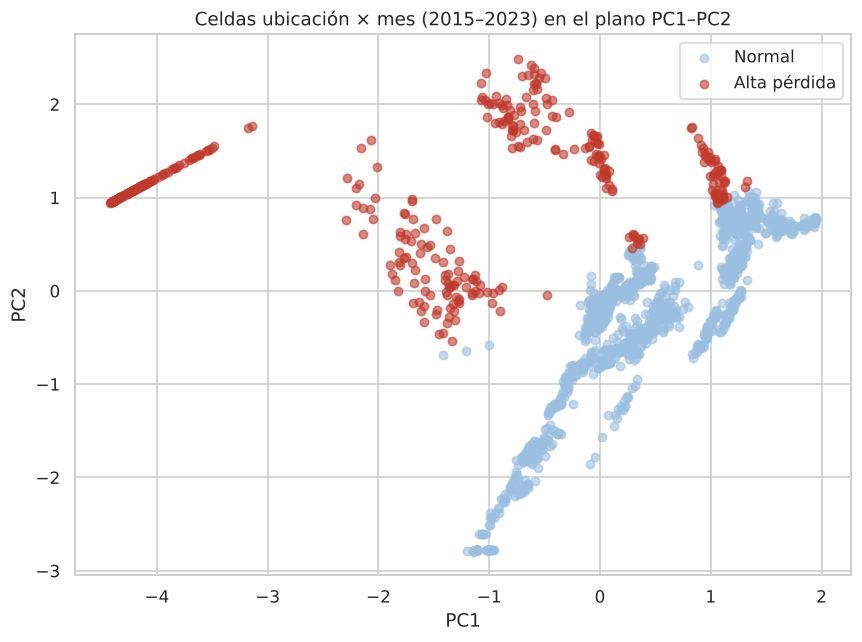

In [44]:
pca = PCA().fit(X_tr_c)

varianza = pd.DataFrame({
    "componente": [f"PC{i + 1}" for i in range(len(VARIABLES_PERFIL))],
    "varianza_explicada": pca.explained_variance_ratio_,
    "acumulada": np.cumsum(pca.explained_variance_ratio_),
})
print("Varianza explicada por componente (entrenamiento):")
print(varianza.round(3).to_string(index=False))

cargas = pd.DataFrame(pca.components_, columns=VARIABLES_PERFIL,
                      index=[f"PC{i + 1}" for i in range(len(VARIABLES_PERFIL))])
print("\nCargas de cada variable en cada componente:")
print(cargas.round(3).to_string())

X_tr_pca = pca.transform(X_tr_c)
fig, ax = plt.subplots(figsize=(8, 6))
for valor, color, etiqueta in [(0, "#9bbfe0", "Normal"), (1, "#c0392b", "Alta pérdida")]:
    m = train_c["alta_perdida"].values == valor
    ax.scatter(X_tr_pca[m, 0], X_tr_pca[m, 1], s=30, alpha=0.6, color=color, label=etiqueta)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Celdas ubicación × mes (2015–2023) en el plano PC1–PC2")
ax.legend()
plt.tight_layout()
plt.show()

**Explicación – PCA**

Ajustamos PCA sobre las tres variables escaladas, usando solo datos de 2015–2023. PCA busca nuevos ejes, que son combinaciones lineales de las variables originales. El primer eje captura la mayor variación posible de los datos, el segundo la mayor variación que queda y que es perpendicular al primero, y así sucesivamente. Para cada eje calculamos dos cosas: la **varianza explicada** (qué fracción de la variación total captura) y las **cargas** (el peso de cada variable en ese eje).

PCA responde dos preguntas del análisis. La primera es cuantitativa: cuántas dimensiones independientes tiene realmente el problema. Si las tres variables fueran independientes, cada componente explicaría cerca de un tercio de la variación. Si dos componentes explican casi todo, en la práctica el problema tiene dos dimensiones. La segunda es visual: proyectar las celdas en dos ejes para ver si las de alta pérdida forman una zona reconocible.

El escalado es obligatorio antes de PCA, porque PCA depende de la escala de las variables. El volumen en Mcf tiene valores de millones y la tasa va de 0 a 1; sin escalar, el volumen dominaría cualquier eje. Por eso el escalador se ajusta solo con entrenamiento y después se aplica a verificación.

**Lectura de la salida:**

*Varianza explicada:*

| Componente | Varianza explicada | Acumulada |
|---|---|---|
| PC1 | 61,3 % | 61,3 % |
| PC2 | 34,4 % | 95,7 % |
| PC3 | 4,3 % | 100 % |

*Cargas:*

| Variable | PC1 | PC2 | PC3 |
|---|---|---|---|
| Volumen total (log) | 0,713 | 0,015 | 0,701 |
| Tasa de pérdida | −0,589 | 0,554 | 0,588 |
| Volumen perdido (log) | 0,379 | 0,832 | −0,404 |

El signo de una componente es arbitrario: se puede invertir el eje y la información no cambia. Lo que importa es qué variables tienen peso alto y en qué combinación.

- **PC1** combina volumen total alto con tasa baja. Es el eje de "cuánto se maneja frente a qué proporción se pierde".
- **PC2** combina tasa alta con volumen perdido alto. Es el eje de "cuánto se pierde, en términos absolutos y proporcionales".
- **PC3** explica solo el 4,3 % y mezcla las tres variables sin una lectura clara. Se puede tratar como residuo.

**Lectura del gráfico:** Cada punto es una celda de entrenamiento en el plano formado por PC1 (horizontal) y PC2 (vertical). Los puntos rojos son celdas de alta pérdida y los azules, normales. Si los rojos se concentran en una zona, la clase tiene un patrón definido en esas dos dimensiones. Si están mezclados con los azules, las variables no la distinguen.

**Conclusiones.** Dos componentes explican el 95,7 % de la variación, así que el problema tiene, en la práctica, dos dimensiones: cuánto volumen se maneja y cuánto de él se pierde. Las celdas de alta pérdida se ubican hacia la izquierda y arriba del plano. Su media en PC1 es −1,56, frente a +0,44 de las normales, y en PC2 es +1,08 frente a −0,30. El 79 % de las celdas de alta pérdida (300 de 379) cae en el lado negativo de PC1, contra el 29 % de las normales (386 de 1.349). La separación existe, pero no es total: hay solapamiento, y por eso PCA se usa para describir la estructura y no para clasificar.

### 6.2 - K-Means: ¿hay grupos naturales?

K-Means necesita que le indiquemos k. Elegimos k con dos criterios: el método del codo (inercia) y el coeficiente de Silhouette.

 k    inercia  silhouette
 2 3,015.9000      0.5540
 3 1,739.5000      0.4260
 4 1,178.2000      0.4770
 5   730.3000      0.5380
 6   509.7000      0.5770
 7   404.1000      0.5460
 8   318.0000      0.5320

k con mayor Silhouette: 6 | valor: 0.577


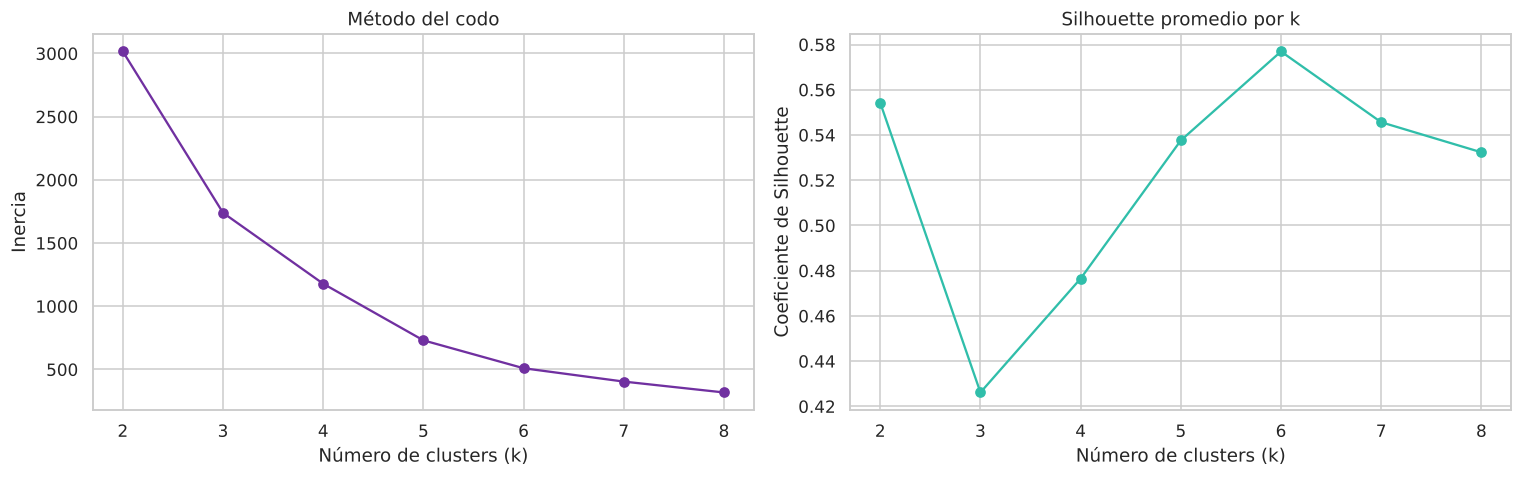

In [45]:
valores_k = list(range(2, 9))
inercias, SILHOUETTES = [], []
for k in valores_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_tr_c)
    inercias.append(km.inertia_)
    SILHOUETTES.append(silhouette_score(X_tr_c, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(valores_k, inercias, "o-", color="#7030A0")
ax[0].set_xlabel("Número de clusters (k)")
ax[0].set_ylabel("Inercia")
ax[0].set_title("Método del codo")
ax[0].set_xticks(valores_k)
ax[1].plot(valores_k, SILHOUETTES, "o-", color="#30BEAA")
ax[1].set_xlabel("Número de clusters (k)")
ax[1].set_ylabel("Coeficiente de Silhouette")
ax[1].set_title("Silhouette promedio por k")
ax[1].set_xticks(valores_k)
plt.tight_layout()
plt.show()

resumen_k = pd.DataFrame({"k": valores_k, "inercia": np.round(inercias, 1), "silhouette": np.round(SILHOUETTES, 3)})
print(resumen_k.to_string(index=False))

mejor_k = valores_k[int(np.argmax(SILHOUETTES))]
print("\nk con mayor Silhouette:", mejor_k, "| valor:", round(max(SILHOUETTES), 3))

**Explicación – elección de k**

Probamos K-Means con valores de k entre 2 y 8, ajustando cada uno con los datos de 2015–2023. K-Means asigna cada celda al centroide más cercano y recalcula los centroides de forma iterativa hasta que las asignaciones dejan de cambiar. Como el resultado depende de la inicialización, usamos 10 inicializaciones aleatorias (`n_init=10`) y nos quedamos con la de menor inercia. Para cada k calculamos dos indicadores:

- **Inercia:** suma de las distancias cuadradas de cada celda a su centroide. Mide qué tan compactos quedan los grupos. Siempre baja al aumentar k.
- **Coeficiente de Silhouette:** para cada celda, *a* es la distancia promedio a las celdas de su propio grupo y *b* es la distancia promedio al grupo más cercano. El valor es (*b* − *a*) / máx(*a*, *b*), que va de −1 a 1. El promedio sobre todas las celdas resume qué tan bien separados están los grupos.

El número de grupos no sale de los datos: hay que elegirlo. Usamos dos criterios porque responden preguntas distintas. El codo busca el punto donde agregar un grupo deja de mejorar la compactación; el Silhouette mide si los grupos están bien separados. Si se usara solo uno, la elección podría quedar sesgada.

**Lectura de la tabla y los gráficos:**

| k | Inercia | Silhouette |
|---|---|---|
| 2 | 3.015,9 | 0,554 |
| 3 | 1.739,5 | 0,426 |
| 4 | 1.178,2 | 0,477 |
| 5 | 730,3 | 0,538 |
| **6** | **509,7** | **0,577** |
| 7 | 404,1 | 0,546 |
| 8 | 318,0 | 0,532 |

En el gráfico del codo, lo que importa es dónde la curva se aplana. En el gráfico del Silhouette, lo que importa es el pico. Un pico claro indica un k con grupos bien separados.

**Conclusiones.** El Silhouette alcanza su máximo en k = 6, con un valor de 0,577. Sin embargo, k = 2 queda muy cerca (0,554), aunque separa las celdas en solo dos grupos, demasiado gruesos para este análisis. El codo no es nítido: la inercia cae fuerte hasta k = 5 o 6, y después se suaviza. Por eso k = 6 es una elección defendible pero orientativa. Con k = 5 (Silhouette 0,538) la partición cambiaría, y no lo comprobamos en el notebook: conviene tenerlo presente al interpretar los clusters.

In [46]:
kmeans = KMeans(n_clusters=mejor_k, n_init=10, random_state=RANDOM_STATE).fit(X_tr_c)
train_c["cluster"] = kmeans.labels_
test_c["cluster"] = kmeans.predict(X_te_c)  # 2024–2025 se asignan con los centroides de 2015–2023

print("Silhouette entrenamiento (2015–2023):", round(silhouette_score(X_tr_c, kmeans.labels_), 3))
print("Silhouette verificación (2024–2025): ", round(silhouette_score(X_te_c, test_c["cluster"]), 3))

tabla_ub = pd.crosstab(train_c["cluster"], train_c["ubicacion"])
print("\nCantidad de celdas de cada ubicación por cluster (entrenamiento):")
print(tabla_ub.to_string())

ari_train = adjusted_rand_score(train_c["ubicacion"], train_c["cluster"])
ari_test = adjusted_rand_score(test_c["ubicacion"], test_c["cluster"])
print(f"\nAdjusted Rand Index contra ubicación – entrenamiento: {ari_train:.3f} | verificación: {ari_test:.3f}")

Silhouette entrenamiento (2015–2023): 0.577
Silhouette verificación (2024–2025):  0.527

Cantidad de celdas de cada ubicación por cluster (entrenamiento):
ubicacion   AR   CA  CO  LA   MT   ND   NM  OK  Offshore Alaska  Offshore Gulf  Offshore Pacific  Otros estados   TX  Tierra indígena (sin estado)   UT   WY
cluster                                                                                                                                                     
0            0    0  82   0    0    0  108   0                0            108                 0              0    0                           108    1  108
1          108    0   0  14    0    0    0  99                0              0                 0              0    0                             0    0    0
2            0    0   0   0    0    0    0   0              108              0                 0              0    0                             0    0    0
3            0    0   0   0    0  108    0   0              

**Explicación – los clusters y la ubicación**

Ajustamos K-Means con k = 6 sobre 2015–2023. Después asignamos las celdas de 2024–2025 con los centroides ya aprendidos, sin reentrenar. Luego cruzamos cada cluster con la ubicación en una tabla de contingencia, que muestra cuántos meses de cada ubicación caen en cada cluster, y calculamos el Adjusted Rand Index (ARI).

Es la comprobación clave del análisis no supervisado. En la clasificación vimos que la ubicación explica casi toda la pérdida significativa. Si los clusters fueran las ubicaciones, el no supervisado no aportaría nada nuevo: solo confirmaría lo que ya sabíamos. Si en cambio los clusters cruzan ubicaciones, aparece un patrón que no depende solo del estado.

**Teoría: ARI.** El Adjusted Rand Index compara dos particiones del mismo conjunto. Cuenta los pares de celdas que están juntos en ambas particiones o separados en ambas, y lo corrige por el acuerdo que se esperaría por azar. Va de 0 (coincidencia de azar) a 1 (coincidencia total). Un valor bajo no significa que el clustering esté mal: significa que los clusters no coinciden con la partición de referencia, que en este caso es la ubicación.

**Lectura de la tabla:** Cada fila es un cluster y cada columna una ubicación. Una ubicación que cae toda en un solo cluster es un grupo claro. Una que se reparte entre varios clusters tiene perfiles distintos a lo largo del tiempo.

| Cluster | Ubicaciones que agrupa (meses en 2015–2023) |
|---|---|
| 0 | NM (108), Offshore Gulf (108), WY (108), Tierra indígena (108), CO (82) |
| 1 | AR (108), OK (99), LA (14) |
| 2 | Offshore Alaska (108) |
| 3 | ND (108), Offshore Pacific (2) |
| 4 | CA, MT, Otros estados, TX (108 cada una), UT (107), LA (94), CO (26), OK (9), Offshore Pacific (6) |
| 5 | Offshore Pacific (100) |

**Conclusiones.** El ARI es 0,282 en entrenamiento y 0,287 en verificación. Es bajo y estable entre periodos, así que los clusters no reproducen las ubicaciones. Lo que agrupa el algoritmo es el perfil de comportamiento, que combina volumen y tasa. Por eso ubicaciones distintas con un perfil parecido caen juntas: el cluster 0 mezcla WY, NM, Offshore Gulf y Tierra indígena, que tienen tasas bajas y volúmenes altos, y el cluster 4 mezcla CA, MT, TX y otras, con tasas bajas y volúmenes medios. Esto es el hallazgo principal de la sección: la pérdida no se agrupa por estado, sino por cuánto volumen maneja cada ubicación y cuánto pierde.

### 6.3 - ¿Los grupos se mantienen en 2024–2025?

Los centroides se aprendieron solo con 2015–2023. Ahora comparamos el perfil de cada cluster en los dos periodos. Si el perfil es parecido, el patrón es estable en el tiempo.

In [47]:
perfil_clusters = pd.concat([
    train_c.assign(periodo="2015–2023"),
    test_c.assign(periodo="2024–2025"),
])

resumen_cl = (perfil_clusters
              .groupby(["periodo", "cluster"])
              .agg(celdas=("tasa_perdida", "size"),
                   tasa_media=("tasa_perdida", "mean"),
                   vol_total_mediano=("log_vol_total", lambda s: np.expm1(s).median()),
                   prop_alta_perdida=("alta_perdida", "mean"))
              .round(3))
print(resumen_cl.to_string())

print("\nUbicaciones más frecuentes por cluster (2015–2023):")
for c in sorted(train_c["cluster"].unique()):
    top = train_c.loc[train_c["cluster"] == c, "ubicacion"].value_counts().head(4)
    print(f"  Cluster {c}: " + ", ".join(f"{u} ({n})" for u, n in top.items()))

                   celdas  tasa_media  vol_total_mediano  prop_alta_perdida
periodo   cluster                                                          
2015–2023 0           515      0.0420    20,477,253.0000             0.1010
          1           221      0.0000       700,949.0000             0.0000
          2           108      1.0000         1,589.0000             1.0000
          3           110      0.5380     1,867,005.0000             1.0000
          4           674      0.0220     1,489,528.0000             0.0180
          5           100      0.3160        43,011.0000             0.9700
2024–2025 0            70      0.0370    13,007,206.0000             0.0430
          1            50      0.0000       620,548.0000             0.0000
          2            17      1.0000         1,292.0000             1.0000
          3            15      0.3150     2,280,076.0000             1.0000
          4           102      0.0230     2,432,747.0000             0.0000
          5 

**Explicación – perfil de los clusters en los dos periodos**

DDescribimos el perfil de cada cluster en 2015–2023 y en 2024–2025: cantidad de celdas, tasa media, volumen total mediano y proporción de celdas de alta pérdida. Después comparamos ambos periodos cluster por cluster.

LLos centroides se aprendieron con 2015–2023, así que el perfil de entrenamiento describe lo que el algoritmo aprendió. El perfil de verificación describe lo que pasó después. Si los dos coinciden, el grupo es un patrón persistente. Si no coinciden, el grupo describió un momento y no un comportamiento estable. Es la misma pregunta del feedback 2, aplicada al no supervisado.

**Lectura de la tabla:** un cluster con tasa media alta y proporción de alta pérdida cercana a 1 es un grupo de pérdida severa. Un cluster con volumen mediano muy alto y tasa baja es un grupo de mucho volumen con poca pérdida relativa. Un cambio en tasa o en volumen entre periodos indica que el grupo se movió.

| Periodo | Cluster | Celdas | Tasa media | Volumen mediano (Mcf) | Prop. alta pérdida |
|---|---|---|---|---|---|
| 2015–2023 | 0 | 515 | 0,042 | 20.477.253 | 0,101 |
| 2015–2023 | 1 | 221 | 0,000 | 700.949 | 0,000 |
| 2015–2023 | 2 | 108 | 1,000 | 1.589 | 1,000 |
| 2015–2023 | 3 | 110 | 0,538 | 1.867.005 | 1,000 |
| 2015–2023 | 4 | 674 | 0,022 | 1.489.528 | 0,018 |
| 2015–2023 | 5 | 100 | 0,316 | 43.011 | 0,970 |
| 2024–2025 | 0 | 70 | 0,037 | 13.007.206 | 0,043 |
| 2024–2025 | 1 | 50 | 0,000 | 620.548 | 0,000 |
| 2024–2025 | 2 | 17 | 1,000 | 1.292 | 1,000 |
| 2024–2025 | 3 | 15 | 0,315 | 2.280.076 | 1,000 |
| 2024–2025 | 4 | 102 | 0,023 | 2.432.747 | 0,000 |
| 2024–2025 | 5 | 18 | 0,319 | 52.518 | 1,000 |

**Conclusiones.**

- **Clusters estables:** el 1, el 2 y el 5 mantienen su tasa media y su proporción de alta pérdida en ambos periodos. El 2 es el grupo de pérdida total (Offshore Alaska, tasa 1,0) y el 1 es el de pérdida nula (AR, OK, LA).
- **Cluster 3:** su tasa media baja de 0,538 a 0,315, pero el grupo sigue siendo el de ND. La causa es que la tasa de ND baja de 0,533 a 0,301 entre periodos: el cluster no cambió de composición, cambió el nivel de pérdida de su única ubicación. Por eso sigue dentro del grupo de alta pérdida.
- **Cluster 0:** el volumen mediano baja de unos 20,5 millones a unos 13,0 millones de Mcf. Ese cambio es el que mueve a CO fuera de este cluster.
- **Cluster 4:** el volumen mediano sube de 1,5 a 2,4 millones de Mcf, y ahí se incorporan LA y otras celdas de bajo volumen.

Los cambios de volumen, más que los de tasa, son los que reorganizan los grupos entre periodos. Esto se ve con detalle en la tabla de estabilidad por ubicación.

In [48]:
# Estabilidad por ubicación: ¿en qué cluster cae la mayoría de sus meses, y se mantiene en 2024–2025?
filas = []
for u, sub in train_c.groupby("ubicacion"):
    dominante = sub["cluster"].value_counts()
    c = dominante.index[0]
    st = test_c[test_c["ubicacion"] == u]
    filas.append({
        "ubicacion": u,
        "cluster_dominante": c,
        "% meses 2015–2023 en ese cluster": round(dominante.iloc[0] / len(sub) * 100, 1),
        "% meses 2024–2025 en ese cluster": round((st["cluster"] == c).mean() * 100, 1),
    })
estabilidad = pd.DataFrame(filas).set_index("ubicacion")
print(estabilidad.to_string())
print(f"\nPromedio: {estabilidad.iloc[:, 1].mean():.1f} % en 2015–2023 | {estabilidad.iloc[:, 2].mean():.1f} % en 2024–2025")

                              cluster_dominante  % meses 2015–2023 en ese cluster  % meses 2024–2025 en ese cluster
ubicacion                                                                                                          
AR                                            1                          100.0000                          100.0000
CA                                            4                          100.0000                           94.1000
CO                                            0                           75.9000                            0.0000
LA                                            4                           87.0000                           29.4000
MT                                            4                          100.0000                          100.0000
ND                                            3                          100.0000                           88.2000
NM                                            0                         

**Explicación – estabilidad por ubicación**

Para cada ubicación buscamos el cluster en el que cae la mayor parte de sus meses en 2015–2023 (su cluster dominante). Después medimos qué porcentaje de sus meses de 2024–2025 sigue en ese mismo cluster.

La tabla de cruce con ubicación mostró que los clusters no son las ubicaciones. Esta tabla responde otra pregunta: si el comportamiento de una ubicación es estable, ¿sus meses siguen cayendo en el mismo grupo? Es una medida de estabilidad individual, más fina que el promedio de los clusters.

**Lectura de la tabla:** un porcentaje cercano a 100 % en las dos columnas indica que la ubicación mantuvo su perfil. Una caída fuerte entre columnas indica que su comportamiento cambió en 2024–2025, y esos casos merecen revisión.

**Conclusiones.** En promedio, el 96,6 % de los meses de cada ubicación cae en su cluster dominante en 2015–2023, y el 86,8 % sigue ahí en 2024–2025. La mayoría de las ubicaciones se mantiene estable: AR, MT, NM, OK, WY y Offshore Alaska no cambian. Hay dos excepciones claras, y las dos tienen la misma causa:

- **CO** cae de 75,9 % a 0 %. Sale del cluster 0 por completo, porque su volumen mediano baja de 32 a 22 millones de Mcf.
- **LA** cae de 87,0 % a 29,4 %. Pasa al cluster 1 porque su volumen mediano sube de 1,2 a 3,5 millones de Mcf.

En ambos casos la tasa de pérdida casi no cambia (cerca de cero), y lo que se mueve es el volumen. Esto importa para el monitoreo: un análisis que mirara solo la tasa no detectaría estos cambios, porque la pérdida relativa sigue igual. El clustering sí los detecta, porque incluye el volumen en su perfil.

### 6.4 - DBSCAN (opcional): meses atípicos

Opcional, como análisis exploratorio. DBSCAN no pide k. Agrupa celdas que están densamente juntas y marca como *ruido* las que quedan aisladas. En nuestro caso, el ruido serían celdas cuyo perfil no se parece al de ninguna otra: meses atípicos.

Elegimos eps con la distancia al 5.º vecino más cercano.

Percentiles de la distancia al vecino:
p50   0.0370
p75   0.0600
p90   0.1000
p95   0.1500
p99   0.2710


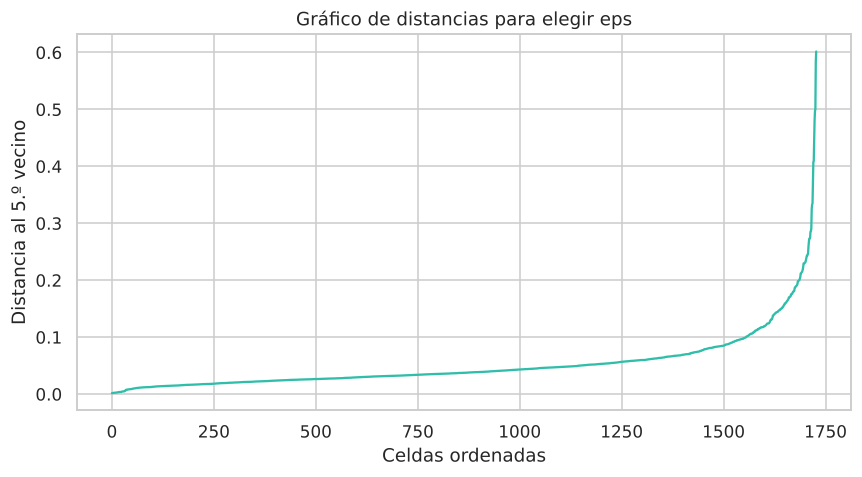

In [49]:
K_NEIGHBORS = 5
vecinos = NearestNeighbors(n_neighbors=K_NEIGHBORS).fit(X_tr_c)
distancias, _ = vecinos.kneighbors(X_tr_c)
dist_k = np.sort(distancias[:, -1])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(dist_k, color="#30BEAA")
ax.set_xlabel("Celdas ordenadas")
ax.set_ylabel(f"Distancia al {K_NEIGHBORS}.º vecino")
ax.set_title("Gráfico de distancias para elegir eps")
plt.tight_layout()
plt.show()

print("Percentiles de la distancia al vecino:")
print(pd.Series(np.percentile(dist_k, [50, 75, 90, 95, 99]), index=["p50", "p75", "p90", "p95", "p99"]).round(3).to_string())

**Explicación**

Antes de correr DBSCAN hay que elegir `eps`. Para eso calculamos la distancia de cada celda a su quinto vecino más cercano (`K_NEIGHBORS = 5`) y ordenamos esas distancias de menor a mayor.

En DBSCAN, `min_samples` define cuántos vecinos necesita una celda para formar parte de una zona densa. Lo fijamos igual a `K_NEIGHBORS`, así que la distancia al quinto vecino es la escala natural para medir densidad.

**Lectura del gráfico**

La curva empieza casi plana: la mayoría de las celdas tienen vecinos cercanos. Después sube en la cola, donde están las celdas aisladas. El punto donde la curva empieza a subir fuerte es el valor razonable para `eps`.

**Conclusión**

Los percentiles muestran que la subida ocurre entre el p95 (0,15) y el p99 (0,27). Por eso se elige `eps = 0,2`. Es un criterio visual, y por eso los resultados de DBSCAN se presentan como exploración.

In [50]:
EPS = 0.2   # codo del gráfico de distancias: entre el p95 (0,15) y el p99 (0,27)
dbscan = DBSCAN(eps=EPS, min_samples=K_NEIGHBORS).fit(X_tr_c)
train_c["cluster_dbscan"] = dbscan.labels_

print("Clusters encontrados:", len(set(dbscan.labels_) - {-1}))
print("Celdas marcadas como ruido:", int((dbscan.labels_ == -1).sum()), "de", len(train_c))

ruido = train_c[train_c["cluster_dbscan"] == -1].sort_values("tasa_perdida", ascending=False)
print("\nCeldas atípicas (ruido), ordenadas por tasa:")
print(ruido[["ubicacion", "production_date", "tasa_perdida", "log_vol_total"]].head(15).to_string(index=False))

sin_ruido = train_c["cluster_dbscan"] != -1
if train_c.loc[sin_ruido, "cluster_dbscan"].nunique() > 1:
    print(f"\nSilhouette DBSCAN (sin ruido): {silhouette_score(X_tr_c[sin_ruido.values], train_c.loc[sin_ruido, 'cluster_dbscan']):.3f}")

Clusters encontrados: 9
Celdas marcadas como ruido: 18 de 1728

Celdas atípicas (ruido), ordenadas por tasa:
       ubicacion production_date  tasa_perdida  log_vol_total
 Offshore Alaska      2020-11-01        1.0000         9.8850
 Offshore Alaska      2020-12-01        1.0000         9.9822
              ND      2017-10-01        0.7849        14.1199
Offshore Pacific      2020-06-01        0.7712        11.4818
Offshore Pacific      2015-10-01        0.7619        11.2075
Offshore Pacific      2023-02-01        0.6973        10.5637
Offshore Pacific      2020-05-01        0.6830        11.1521
Offshore Pacific      2022-08-01        0.6622        10.6557
Offshore Pacific      2023-03-01        0.6558        10.5523
Offshore Pacific      2022-06-01        0.5782         9.9504
Offshore Pacific      2022-09-01        0.5144        10.0003
Offshore Pacific      2016-05-01        0.3955        11.3229
Offshore Pacific      2015-05-01        0.1011        12.3506
Offshore Pacific      2

**Explicación – DBSCAN y meses atípicos**

Elegimos eps mirando la curva de distancias y después aplicamos DBSCAN sobre 2015–2023.

A diferencia de K-Means, DBSCAN no obliga a que cada celda pertenezca a un grupo. Las celdas que quedan aisladas se marcan como ruido, y ese ruido es la información útil: son meses cuyo perfil es raro dentro de su propio contexto.

La curva de distancias muestra un punto donde la distancia empieza a crecer rápido; eps se elige cerca de ese codo. Si el eps es muy chico, casi todo queda como ruido; si es muy grande, todo queda en un solo grupo. Como los datos no tienen una densidad muy marcada, el resultado depende bastante de eps, así que lo presentamos como exploración y no como resultado.

## 6.5 - Conclusiones de la sección no supervisada

**Qué encontramos**

1. **PCA:** dos componentes alcanzan para casi todo. PC1 explica el 61 % de la variación y PC2 el 34 % (96 % acumulado). PC1 contrasta volumen total alto con tasa baja. PC2 está dominado por el volumen perdido. PC3 explica solo el 4 %, así que las tres variables son en la práctica dos dimensiones.

2. **K-Means:** el Silhouette elige k = 6 (0,577 en 2015–2023 y 0,527 en 2024–2025). El método del codo no marca un quiebre claro, así que la elección es orientativa.

3. **Los clusters no son las ubicaciones:** el Adjusted Rand Index contra `ubicacion` es 0,28 en entrenamiento y 0,29 en verificación. Los clusters agrupan ubicaciones con perfiles parecidos. Por ejemplo, el cluster 0 reúne WY, NM, Tierra indígena, Offshore Gulf y, en 2015–2023, CO. ND (cluster 3) y Offshore Alaska (cluster 2) quedan solos.

4. **Estabilidad temporal:** en promedio, el 96,6 % de los meses de cada ubicación cae en su cluster dominante en 2015–2023, y el 86,8 % sigue ahí en 2024–2025. La mayoría de las ubicaciones no cambia. Las excepciones son CO y LA:
   - **CO** pasa del cluster 0 al cluster 4. La mediana de volumen por celda baja de 32 a 22 millones de Mcf, y la tasa queda casi en cero en ambos periodos.
   - **LA** pasa del cluster 4 al cluster 1. La mediana sube de 1,2 a 3,5 millones de Mcf, y la tasa también queda casi en cero.

5. **DBSCAN (exploratorio):** con eps = 0,2 aparecen 9 grupos y 18 celdas de ruido (1 %). El ruido son meses atípicos: 11 de Offshore Pacific, con pérdidas altas en varios años; 2 de Offshore Alaska en noviembre y diciembre de 2020, con tasa 100 %; ND en octubre de 2017; tres meses de LA en 2023 con pérdida cero y volumen muy alto; y UT en junio de 2023. El Silhouette sin ruido es 0,357, menor que el de K-Means, así que DBSCAN no separa mejor los grupos. Sirve para detectar meses raros, no como agrupación final.

**Qué significa para nuestra pregunta**

- Confirma lo que vimos en la clasificación: la pérdida tiene un patrón estable por ubicación.
- Agrega algo nuevo: el no supervisado no reproduce las ubicaciones, sino que agrupa por volumen y pérdida. Además, detecta cambios de volumen en CO y LA que la clasificación no veía, porque la tasa no se movió.
- Para monitoreo, la señal relevante es el cambio de volumen. Un modelo que usara solo la tasa no lo detectaría.

**Limitaciones**

- El número de clusters depende de un criterio que no es concluyente (silhouette frente a codo).
- El resultado de DBSCAN depende mucho de eps.
- 2024–2025 es un periodo parcial (enero a mayo de 2025), y las medianas de volumen por ubicación se calcularon con muy pocas celdas en ese periodo.

# Parte 7 - Conclusiones finales

Este apartado resume el trabajo: la pregunta, los datos, los métodos, los resultados, las respuestas y las limitaciones.

## 7.1 - Pregunta y respuesta corta

**Pregunta:** ¿qué ubicación y época del año se asocian con que una celda ubicación × mes tenga una pérdida significativa de gas (venteo + quema superior al 10 % del volumen total)?

**Respuesta:** la ubicación explica casi toda la pérdida significativa, y ese patrón se mantiene en 2024–2025. Con el umbral del 10 %, la regresión logística llega a ROC-AUC de 0,981 y recall de 0,962, sin falsas alarmas. El resultado depende del umbral: con 5 % baja a 0,883 y con 15 % llega a 1,000.

## 7.2 - Resultados principales

**Clasificación de pérdida significativa (verificación 2024–mayo 2025, 272 celdas, 53 positivas):**

| Modelo | ROC-AUC | PR-AUC | Recall | Precisión |
|---|---|---|---|---|
| DUMMY (BASELINE) | 0,500 | 0,195 | 0,000 | – |
| LOGISTIC REGRESSION | 0,981 | 0,975 | 0,962 | 1,000 |
| RANDOM FOREST | 0,981 | 0,976 | 0,962 | 1,000 |
| RATE BY CELL (CEILING) | 0,986 | 0,977 | 0,962 | 1,000 |
| REGRESSION ON RATE (umbral 0,10) | 0,989 | 0,980 | 0,962 | 0,750 |

**Sensibilidad al umbral (regresión logística):**

| Umbral | Positivos en verificación | ROC-AUC | PR-AUC |
|---|---|---|---|
| 5 % | 84 | 0,883 | 0,827 |
| 10 % | 53 | 0,981 | 0,975 |
| 15 % | 50 | 1,000 | 0,998 |

**Análisis no supervisado:**

| Resultado | Valor |
|---|---|
| PCA: varianza explicada por PC1 + PC2 | 95,7 % |
| K-Means elegido (Silhouette) | k = 6, silhouette 0,577 |
| Adjusted Rand Index contra ubicación | 0,28 (los clusters no son las ubicaciones) |
| Estabilidad de la ubicación en su cluster | 96,6 % (2015–2023) → 86,8 % (2024–2025) |
| DBSCAN (eps 0,2): celdas de ruido | 18 de 1.728 (1 %) |

**Figura resumen:**

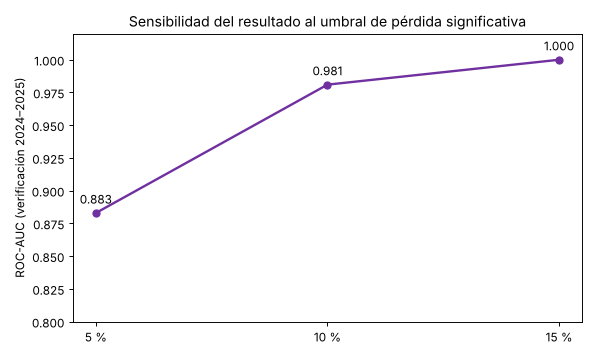

*El ROC-AUC depende del umbral elegido.*

## 7.3 - Preguntas y respuestas

| Pregunta | Respuesta | Evidencia |
|---|---|---|
| ¿La pérdida significativa depende de la ubicación? | Sí, casi por completo | 10 de 16 ubicaciones están separadas perfectamente (sección 3.8) |
| ¿Qué tan bien se predice la pérdida significativa? | Muy bien con las variables actuales | ROC-AUC 0,981 y recall 0,962 en 2024–2025, sin falsas alarmas (sección 5.1) |
| ¿El resultado es robusto al umbral del 10 %? | No del todo | ROC-AUC de 0,883 con 5 % y de 1,000 con 15 % (sección 5.3) |
| ¿Se mantiene en el tiempo? | Sí para la clasificación; con excepciones en volumen | Corte temporal 2023/2024. CO y LA cambian de grupo por volumen (secciones 5 y 6) |
| ¿Hay patrones más allá de la ubicación? | Sí, por perfil de volumen y pérdida | Clusters que no coinciden con ubicaciones; meses atípicos en Offshore Pacific (sección 6) |
| ¿La época del año aporta información? | No se evaluó por separado | La estación entra en el modelo, pero no se midió su aporte en forma aislada |

## 7.4 - Respuesta al feedback de la Pre Entrega 3:

- **Volumen, no solo presencia de pérdida:** la tasa de pérdida está ponderada por el volumen total de cada celda.
- **Unidad de análisis:** pasamos de renglón administrativo a celda ubicación × mes. No llegamos al nivel de pozo, porque el dataset no tiene identificador de pozo ni de operador.
- **Umbral:** se fijó en 10 % como regla y se evalúa su sensibilidad.
- **Partición temporal:** entrenamiento 2015–2023 y verificación 2024–mayo 2025, con validación cruzada temporal.